# Proyecto: Productividad de los trabajadores en una fábrica de ropa
**Curso:** Data Analytics en Gestión Industrial – Universidad de Ibagué
**Integrantes:**
- Ricardo Alvarez Zapata — cód. 2320221005
- Juan David Díaz Riaño — cód. 2320221023
- Andres Urueña — cód. 2320212016



---
# FASE 1 — Contexto y dataset

### El problema
En una fábrica de ropa (*garment industry*) casi todo el trabajo es manual. Cada día la gerencia le pone a cada equipo una **meta de productividad**, pero **muchos equipos no la cumplen**. Cuando un equipo no cumple, los pedidos se atrasan y hay que pagar horas extra.

**Pregunta principal:** ¿por qué algunos equipos no cumplen su meta y cómo podemos anticiparlo?

### Ficha técnica del dataset
| Dato | Valor |
|---|---|
| Nombre | Productivity Prediction of Garment Employees |
| Origen | UCI Machine Learning Repository (dataset 597), listado en *awesome-industrial-datasets* |
| Enlace | https://archive.ics.uci.edu/dataset/597/productivity+prediction+of+garment+employees |
| DOI | 10.24432/C51S6D |
| Autores | Abdullah Al Imran, Md Shamsur Rahim, Tanvir Ahmed (2021) |
| Formato | Archivo CSV (`garments_worker_productivity.csv`) |
| Tamaño | 1197 filas × 15 columnas (≈ 95 KB) |
| Periodo de los datos | Enero a marzo de 2015, una fábrica en Bangladesh |
| Última actualización | Publicado en UCI el 2 de agosto de 2020 |
| Licencia | Creative Commons Attribution 4.0 (CC BY 4.0): se puede usar citando la fuente |
| Para qué sirve | Clasificación (cumple / no cumple) y regresión (predecir la productividad) |

### ¿Por qué es valioso este dato abierto?
- Son **datos reales** de una fábrica, recogidos a mano y revisados por expertos de la industria.
- Es **gratis y público**: cualquier empresa puede usarlo para comparar o para probar métodos antes de invertir en recolectar sus propios datos.
- Permite tomar decisiones con **evidencia** (metas, incentivos, tamaño de equipos) y no solo por intuición.

---
# FASE 2 — ETL (Extraer, Transformar y Cargar)

## 2.1 Extraer: cargar los datos


In [2]:
import pandas as pd

df = pd.read_csv('../datasets/garments_worker_productivity.csv')

df.head()

,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
0,1/1/2015,Quarter1,sweing,Thursday,8,0.80,26.16,1108.0,7080,98,0.0,0,0,59.0,0.940725
1,1/1/2015,Quarter1,finishing,Thursday,1,0.75,3.94,NaN,960,0,0.0,0,0,8.0,0.886500
2,1/1/2015,Quarter1,sweing,Thursday,11,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
3,1/1/2015,Quarter1,sweing,Thursday,12,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
4,1/1/2015,Quarter1,sweing,Thursday,6,0.80,25.90,1170.0,1920,50,0.0,0,0,56.0,0.800382


In [3]:
# Guardamos una copia de los datos SIN limpiar para compararlos al final (reporte de calidad)
df_original = df.copy()

## 2.2 Revisar cómo vienen los datos

In [4]:
print(df.columns)

Index(['date', 'quarter', 'department', 'day', 'team', 'targeted_productivity',
       'smv', 'wip', 'over_time', 'incentive', 'idle_time', 'idle_men',
       'no_of_style_change', 'no_of_workers', 'actual_productivity'],
      dtype='str')


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1197 entries, 0 to 1196
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   date                   1197 non-null   str    
 1   quarter                1197 non-null   str    
 2   department             1197 non-null   str    
 3   day                    1197 non-null   str    
 4   team                   1197 non-null   int64  
 5   targeted_productivity  1197 non-null   float64
 6   smv                    1197 non-null   float64
 7   wip                    691 non-null    float64
 8   over_time              1197 non-null   int64  
 9   incentive              1197 non-null   int64  
 10  idle_time              1197 non-null   float64
 11  idle_men               1197 non-null   int64  
 12  no_of_style_change     1197 non-null   int64  
 13  no_of_workers          1197 non-null   float64
 14  actual_productivity    1197 non-null   float64
dtypes: float64(6), 

 1197 filas y 15 columnas. Casi todas las columnas están completas, **menos `wip`**, que solo tiene 691 datos (le faltan 506). La columna `date` está guardada como **texto**, no como fecha.

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
team,1197.0,6.426901,3.463963,1.000000,3.000000,6.000000,9.000000,12.000000
targeted_productivity,1197.0,0.729632,0.097891,0.070000,0.700000,0.750000,0.800000,0.800000
smv,1197.0,15.062172,10.943219,2.900000,3.940000,15.260000,24.260000,54.560000
wip,691.0,1190.465991,1837.455001,7.000000,774.500000,1039.000000,1252.500000,23122.000000
over_time,1197.0,4567.460317,3348.823563,0.000000,1440.000000,3960.000000,6960.000000,25920.000000
incentive,1197.0,38.210526,160.182643,0.000000,0.000000,0.000000,50.000000,3600.000000
idle_time,1197.0,0.730159,12.709757,0.000000,0.000000,0.000000,0.000000,300.000000
idle_men,1197.0,0.369256,3.268987,0.000000,0.000000,0.000000,0.000000,45.000000
no_of_style_change,1197.0,0.150376,0.427848,0.000000,0.000000,0.000000,0.000000,2.000000
no_of_workers,1197.0,34.609858,22.197687,2.000000,9.000000,34.000000,57.000000,89.000000


 `targeted_productivity` (la meta) tiene un mínimo de **0.07**, muy raro porque las demás metas están entre 0.35 y 0.80. `actual_productivity` (la productividad real) llega hasta **1.12**, o sea más del 100 %.

## 2.3 Transformar: limpiar los datos

### Duplicados y vacíos (primera revisión)


In [7]:
df.drop_duplicates()
df.dropna()

,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
0,1/1/2015,Quarter1,sweing,Thursday,8,0.80,26.16,1108.0,7080,98,0.0,0,0,59.0,0.940725
2,1/1/2015,Quarter1,sweing,Thursday,11,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
3,1/1/2015,Quarter1,sweing,Thursday,12,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
4,1/1/2015,Quarter1,sweing,Thursday,6,0.80,25.90,1170.0,1920,50,0.0,0,0,56.0,0.800382
5,1/1/2015,Quarter1,sweing,Thursday,7,0.80,25.90,984.0,6720,38,0.0,0,0,56.0,0.800125
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1187,3/11/2015,Quarter2,sweing,Wednesday,4,0.75,26.82,1054.0,7080,45,0.0,0,0,59.0,0.750051
1188,3/11/2015,Quarter2,sweing,Wednesday,5,0.70,26.82,992.0,6960,30,0.0,0,1,58.0,0.700557
1189,3/11/2015,Quarter2,sweing,Wednesday,8,0.70,30.48,914.0,6840,30,0.0,0,1,57.0,0.700505
1190,3/11/2015,Quarter2,sweing,Wednesday,6,0.70,23.41,1128.0,4560,40,0.0,0,1,38.0,0.700246


In [8]:
df['department'].unique()

<StringArray>
['sweing', 'finishing ', 'finishing']
Length: 3, dtype: str

In [9]:
df['department'].value_counts()

department
sweing        691
finishing     257
finishing     249
Name: count, dtype: int64

In [10]:
df['department'] = df['department'].replace('sweing', 'sewing')
df['department'] = df['department'].replace('finishing ', 'finishing')

df['department'].value_counts()

department
sewing       691
finishing    506
Name: count, dtype: int64

### Datos vacíos (nulos)

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1197 entries, 0 to 1196
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   date                   1197 non-null   str    
 1   quarter                1197 non-null   str    
 2   department             1197 non-null   str    
 3   day                    1197 non-null   str    
 4   team                   1197 non-null   int64  
 5   targeted_productivity  1197 non-null   float64
 6   smv                    1197 non-null   float64
 7   wip                    691 non-null    float64
 8   over_time              1197 non-null   int64  
 9   incentive              1197 non-null   int64  
 10  idle_time              1197 non-null   float64
 11  idle_men               1197 non-null   int64  
 12  no_of_style_change     1197 non-null   int64  
 13  no_of_workers          1197 non-null   float64
 14  actual_productivity    1197 non-null   float64
dtypes: float64(6), 

In [12]:
df = df.drop_duplicates()

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1197 entries, 0 to 1196
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   date                   1197 non-null   str    
 1   quarter                1197 non-null   str    
 2   department             1197 non-null   str    
 3   day                    1197 non-null   str    
 4   team                   1197 non-null   int64  
 5   targeted_productivity  1197 non-null   float64
 6   smv                    1197 non-null   float64
 7   wip                    691 non-null    float64
 8   over_time              1197 non-null   int64  
 9   incentive              1197 non-null   int64  
 10  idle_time              1197 non-null   float64
 11  idle_men               1197 non-null   int64  
 12  no_of_style_change     1197 non-null   int64  
 13  no_of_workers          1197 non-null   float64
 14  actual_productivity    1197 non-null   float64
dtypes: float64(6), 

 Siguen siendo 1197 filas: **no había filas repetidas**.

### Valores atípicos (datos raros)

In [13]:
df['targeted_productivity'].value_counts()


targeted_productivity
0.80    540
0.70    242
0.75    216
0.65     63
0.60     57
0.50     49
0.35     27
0.40      2
0.07      1
Name: count, dtype: int64

In [14]:
df[df['targeted_productivity'] < 0.3]

,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
633,2/5/2015,Quarter1,sewing,Thursday,7,0.07,24.26,1608.0,6960,0,0.0,0,0,58.0,0.522845


In [15]:
df['targeted_productivity'] = df['targeted_productivity'].replace(0.07, 0.7)

df['targeted_productivity'].value_counts()

targeted_productivity
0.80    540
0.70    243
0.75    216
0.65     63
0.60     57
0.50     49
0.35     27
0.40      2
Name: count, dtype: int64

In [16]:
df[df['actual_productivity'] > 1]

,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
337,1/20/2015,Quarter3,finishing,Tuesday,5,0.70,4.15,NaN,1440,0,0.0,0,0,8.0,1.033570
437,1/26/2015,Quarter4,finishing,Monday,3,0.75,3.94,NaN,1800,0,0.0,0,0,10.0,1.059621
456,1/27/2015,Quarter4,sewing,Tuesday,2,0.75,22.52,1635.0,6840,119,0.0,0,0,57.0,1.000230
457,1/27/2015,Quarter4,sewing,Tuesday,3,0.75,22.52,1299.0,6840,119,0.0,0,0,57.0,1.000230
477,1/28/2015,Quarter4,sewing,Wednesday,2,0.80,22.52,1559.0,6840,90,0.0,0,0,57.0,1.000230
478,1/28/2015,Quarter4,sewing,Wednesday,3,0.80,22.52,1350.0,6840,113,0.0,0,0,57.0,1.000230
498,1/29/2015,Quarter5,sewing,Thursday,2,0.80,22.52,1416.0,6840,113,0.0,0,0,57.0,1.000230
518,1/31/2015,Quarter5,sewing,Saturday,3,0.80,22.52,1136.0,6960,113,0.0,0,0,58.0,1.000457
519,1/31/2015,Quarter5,sewing,Saturday,2,0.80,22.52,1397.0,6840,113,0.0,0,0,57.0,1.000230
542,2/1/2015,Quarter1,finishing,Sunday,8,0.65,4.15,NaN,960,0,0.0,0,0,8.0,1.011562


In [17]:
df["date"] = pd.to_datetime(df["date"], format="%m/%d/%Y")
print(df["date"].dtype, "| desde", df["date"].min().date(), "hasta", df["date"].max().date())

datetime64[us] | desde 2015-01-01 hasta 2015-03-11


### Nuevas variables (KPIs)
- **productividad_%:** la productividad en porcentaje.
- **meta_%:** la meta en porcentaje.
- **brecha:** productividad real − meta. Si es positiva, el equipo **superó** la meta; si es negativa, **no llegó**.

In [18]:
df['productividad_%'] = df['actual_productivity'] * 100
df['meta_%'] = df['targeted_productivity'] * 100
df['brecha'] = df['actual_productivity'] - df['targeted_productivity']

df.head()

,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity,productividad_%,meta_%,brecha
0,2015-01-01,Quarter1,sewing,Thursday,8,0.80,26.16,1108.0,7080,98,0.0,0,0,59.0,0.940725,94.072542,80.0,0.140725
1,2015-01-01,Quarter1,finishing,Thursday,1,0.75,3.94,NaN,960,0,0.0,0,0,8.0,0.886500,88.650000,75.0,0.136500
2,2015-01-01,Quarter1,sewing,Thursday,11,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570,80.057049,80.0,0.000570
3,2015-01-01,Quarter1,sewing,Thursday,12,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570,80.057049,80.0,0.000570
4,2015-01-01,Quarter1,sewing,Thursday,6,0.80,25.90,1170.0,1920,50,0.0,0,0,56.0,0.800382,80.038194,80.0,0.000382


## 2.4 Cargar: guardar los datos limpios

In [19]:
df.to_csv('../datasets/garments_limpio.csv', index=False)

In [20]:
reporte_calidad = pd.DataFrame([
    {"Problema": "Filas totales", "Antes": len(df_original), "Después": len(df),
     "Qué hicimos": "No se borró ninguna fila"},
    {"Problema": "Filas duplicadas", "Antes": df_original.duplicated().sum(), "Después": df.duplicated().sum(),
     "Qué hicimos": "drop_duplicates() (no había)"},
    {"Problema": "Vacíos en wip", "Antes": df_original["wip"].isna().sum(), "Después": df["wip"].isna().sum(),
     "Qué hicimos": "Se deja; no se usa en los modelos"},
    {"Problema": "Nombres de departamento distintos", "Antes": df_original["department"].nunique(),
     "Después": df["department"].nunique(), "Qué hicimos": "Corregir 'sweing' y 'finishing '"},
    {"Problema": "Meta = 0.07 (error de digitación)", "Antes": (df_original["targeted_productivity"] == 0.07).sum(),
     "Después": (df["targeted_productivity"] == 0.07).sum(), "Qué hicimos": "Reemplazar por 0.7"},
    {"Problema": "Productividad > 1", "Antes": (df_original["actual_productivity"] > 1).sum(),
     "Después": (df["actual_productivity"] > 1).sum(), "Qué hicimos": "Se dejan (son posibles)"},
    {"Problema": "Columna date como texto", "Antes": str(df_original["date"].dtype),
     "Después": str(df["date"].dtype), "Qué hicimos": "Convertir a fecha"},
])
reporte_calidad

,Problema,Antes,Después,Qué hicimos
0,Filas totales,1197,1197,No se borró ninguna fila
1,Filas duplicadas,0,0,drop_duplicates() (no había)
2,Vacíos en wip,506,506,Se deja; no se usa en los modelos
3,Nombres de departamento distintos,3,2,Corregir 'sweing' y 'finishing '
4,Meta = 0.07 (error de digitación),1,0,Reemplazar por 0.7
5,Productividad > 1,37,37,Se dejan (son posibles)
6,Columna date como texto,str,datetime64[us],Convertir a fecha


### Modelo de datos (cómo organizamos la información)
Usamos una estructura sencilla tipo **Data Lake local** con dos zonas:

```text
mgi_dataanalitica-main/
├── datasets/
│   ├── garments_worker_productivity.csv   ← ZONA RAW: datos originales (no se tocan)
│   ├── garments_limpio.csv                ← ZONA PROCESADA: datos limpios
│   └── modelo_datos/                      ← tablas relacionales (abajo)
└── Proyecto/
    └── project.ipynb                      ← todo el proceso (ETL, EDA, modelos)
```

Y dentro de la zona procesada, organizamos los datos como un **modelo relacional tipo estrella**: una tabla central de hechos (cada jornada de un equipo) unida a tablas de apoyo (dimensiones):

```text
   dim_fecha (fecha, día, semana del mes, mes)
          │
          ▼
   hechos_produccion (fecha, equipo, departamento, meta, smv, horas extra,
          ▲            incentivo, paros, cambios de estilo, trabajadores, productividad)
          │
   dim_equipo (equipo, departamento)
```

In [21]:
import os
os.makedirs("../datasets/modelo_datos", exist_ok=True)

dim_fecha = (df[["date", "day", "quarter"]].drop_duplicates()
             .assign(mes=lambda t: t["date"].dt.month).sort_values("date"))
dim_equipo = df[["team", "department"]].drop_duplicates().sort_values(["team", "department"])
hechos_produccion = df[["date", "team", "department", "targeted_productivity", "smv", "wip", "over_time",
                        "incentive", "idle_time", "idle_men", "no_of_style_change", "no_of_workers",
                        "actual_productivity", "brecha"]]

dim_fecha.to_csv("../datasets/modelo_datos/dim_fecha.csv", index=False)
dim_equipo.to_csv("../datasets/modelo_datos/dim_equipo.csv", index=False)
hechos_produccion.to_csv("../datasets/modelo_datos/hechos_produccion.csv", index=False)

print("dim_fecha:", dim_fecha.shape, "| dim_equipo:", dim_equipo.shape, "| hechos_produccion:", hechos_produccion.shape)

dim_fecha: (59, 4) | dim_equipo: (24, 2) | hechos_produccion: (1197, 14)


---
# FASE 3 — EDA (Análisis Exploratorio de Datos)

In [22]:
import matplotlib.pyplot as plt

### Estadísticas de la productividad

In [23]:
print('Promedio:', df['actual_productivity'].mean())
print('Mediana:', df['actual_productivity'].median())
print('Mínimo:', df['actual_productivity'].min())
print('Máximo:', df['actual_productivity'].max())

Promedio: 0.7350910969791145
Mediana: 0.773333333
Mínimo: 0.233705476
Máximo: 1.1204375


 En promedio los equipos logran **0.735 (73.5 %)**, casi igual a la meta promedio (0.73). La mediana (0.77) es mayor que el promedio porque hay **algunos días muy malos** (mínimo 0.23) que bajan el promedio.

### Gráfica 1 — Histograma de la productividad

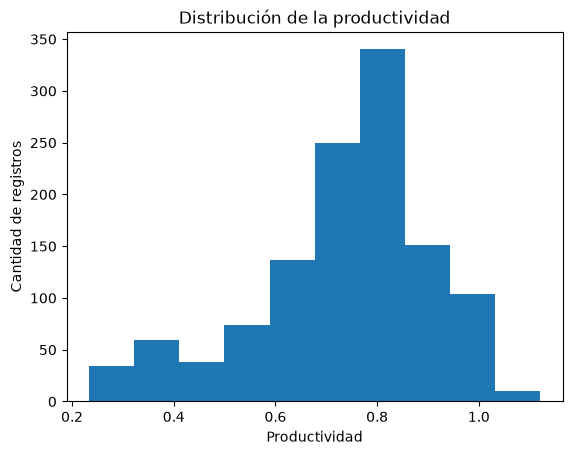

In [24]:
plt.hist(df['actual_productivity'], bins=10)
plt.title('Distribución de la productividad')
plt.xlabel('Productividad')
plt.ylabel('Cantidad de registros')
plt.show()

El grupo más grande de registros está entre **0.7 y 0.85** (≈ 43 %), pero hay una "cola" hacia la izquierda: **≈ 11 %** de las jornadas tienen productividad muy baja (menos de 0.5).
el problema no es que todos rindan poco, sino que **hay días puntuales muy malos**. Hay que encontrar qué los causa.

### KPIs: nuevas variables y cumplimiento de la meta

In [25]:
df['productividad_%'] = df['actual_productivity'] * 100
df['meta_%'] = df['targeted_productivity'] * 100
df['brecha'] = df['actual_productivity'] - df['targeted_productivity']
df['cumplio_meta'] = df['brecha'] >= 0

df.head()


,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity,productividad_%,meta_%,brecha,cumplio_meta
0,2015-01-01,Quarter1,sewing,Thursday,8,0.80,26.16,1108.0,7080,98,0.0,0,0,59.0,0.940725,94.072542,80.0,0.140725,True
1,2015-01-01,Quarter1,finishing,Thursday,1,0.75,3.94,NaN,960,0,0.0,0,0,8.0,0.886500,88.650000,75.0,0.136500,True
2,2015-01-01,Quarter1,sewing,Thursday,11,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570,80.057049,80.0,0.000570,True
3,2015-01-01,Quarter1,sewing,Thursday,12,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570,80.057049,80.0,0.000570,True
4,2015-01-01,Quarter1,sewing,Thursday,6,0.80,25.90,1170.0,1920,50,0.0,0,0,56.0,0.800382,80.038194,80.0,0.000382,True


cumplio_meta
True     874
False    323
Name: count, dtype: int64


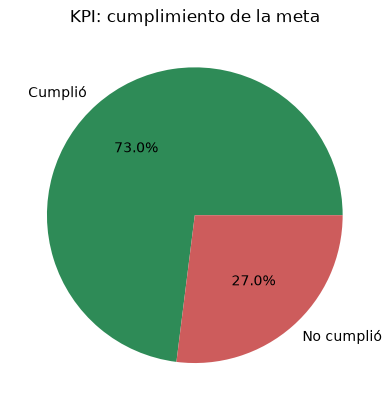

In [26]:
conteo = df["cumplio_meta"].value_counts()
print(conteo)

plt.pie(conteo, labels=["Cumplió", "No cumplió"], autopct="%1.1f%%", colors=["seagreen", "indianred"])
plt.title("KPI: cumplimiento de la meta")
plt.show()

### Gráfica 2 — KPI de cumplimiento (pie)
el **73 %** de las veces el equipo cumplió la meta y el **27 %** no (323 de 1197).
**Qué significa:** **1 de cada 4 jornadas** termina por debajo de la meta. Ese es el problema que queremos reducir.

### Gráfica 3 — Productividad por departamento (boxplot)

department
finishing    0.752951
sewing       0.722013
Name: actual_productivity, dtype: float64


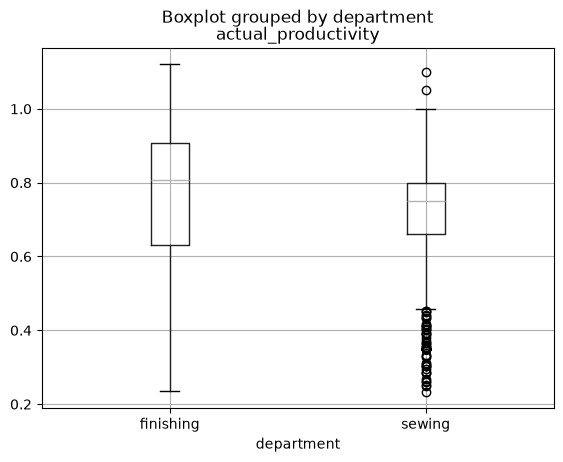

In [27]:
print(df.groupby('department')['actual_productivity'].mean())

df.boxplot(column='actual_productivity', by='department')
plt.show()

 acabado (finishing) tiene un promedio un poco mayor (**0.75**) que costura (sewing, **0.72**), pero su caja es **más alta**: sus resultados cambian mucho de un día a otro.
 acabado es **más inestable**: tiene días muy buenos y días muy malos.

### Gráfica 4 — Productividad por día de la semana (barras)

day
Monday       0.735488
Saturday     0.751929
Sunday       0.728604
Thursday     0.722641
Tuesday      0.742701
Wednesday    0.730462
Name: actual_productivity, dtype: float64


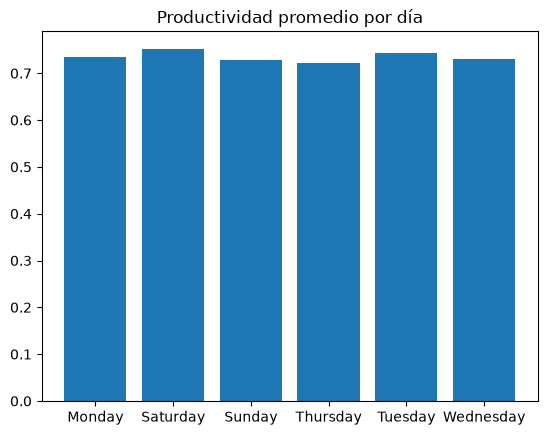

In [28]:
dias = df.groupby('day')['actual_productivity'].mean()
print(dias)

plt.bar(dias.index, dias.values)
plt.title('Productividad promedio por día')
plt.show()

**Qué vemos:** todos los días están entre **0.72 y 0.75**. El jueves es el más bajo y el sábado el más alto. (No hay viernes: es el día de descanso en Bangladesh.) el **día de la semana casi no influye**. El problema está en otro lado.

### Gráfica 5 — Productividad por equipo (barras)

team
1     0.821054
3     0.803880
12    0.779055
2     0.770855
4     0.770035
9     0.734462
10    0.719736
5     0.697981
6     0.685385
11    0.681985
8     0.674148
7     0.668006
Name: actual_productivity, dtype: float64


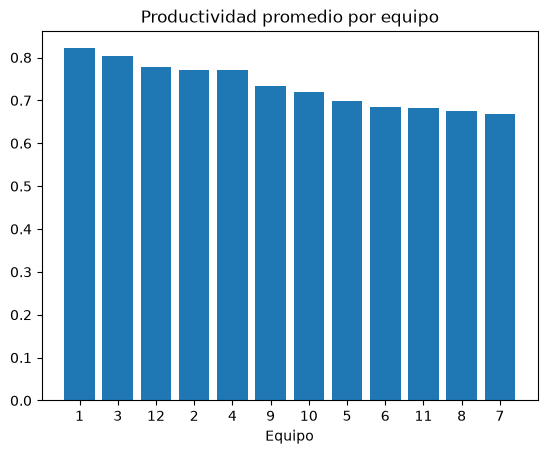

In [29]:
equipos = df.groupby('team')['actual_productivity'].mean().sort_values(ascending=False)
print(equipos)

plt.bar(equipos.index.astype(str), equipos.values)
plt.title('Productividad promedio por equipo')
plt.xlabel('Equipo')
plt.show()

los mejores equipos son el **1 (0.82)** y el **3 (0.80)**; los más bajos son el **7 y el 8 (0.67)**. Hay más de **15 puntos** de diferencia entre el mejor y el peor.
 **el equipo sí importa mucho**. Vale la pena revisar qué hacen distinto los mejores equipos.

### Gráfica 6 — Productividad por semana del mes (línea)

quarter
Quarter1    0.751560
Quarter2    0.743710
Quarter3    0.704759
Quarter4    0.709067
Quarter5    0.826177
Name: actual_productivity, dtype: float64


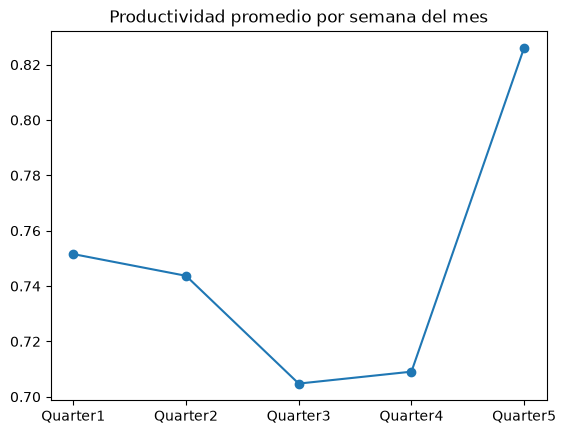

In [30]:
semanas = df.groupby('quarter')['actual_productivity'].mean()
print(semanas)

plt.plot(semanas.index, semanas.values, marker='o')
plt.title('Productividad promedio por semana del mes')
plt.show()

la productividad **baja en las semanas 3 y 4** (≈ 0.70) y sube en la "semana 5" (0.83), que son solo los últimos días del mes (pocos registros).
 a mitad de mes el rendimiento cae; puede ser por cansancio o por acumulación de pedidos.

### Correlación con la productividad

In [31]:
columnas = ['targeted_productivity', 'smv', 'over_time', 'incentive', 'idle_time',
            'idle_men', 'no_of_style_change', 'no_of_workers', 'actual_productivity']

df[columnas].corr()['actual_productivity'].sort_values(ascending=False)

actual_productivity      1.000000
targeted_productivity    0.423148
incentive                0.076538
over_time               -0.054206
no_of_workers           -0.057991
idle_time               -0.080851
smv                     -0.122089
idle_men                -0.181734
no_of_style_change      -0.207366
Name: actual_productivity, dtype: float64

cerca de **+1** = cuando una sube, la otra también; cerca de **−1** = cuando una sube, la otra baja; cerca de **0** = casi no hay relación.


- La **meta** es la más relacionada (+0.42): a meta más alta, productividad más alta.
- Los **cambios de estilo** (−0.21) y los **trabajadores parados** (−0.18) **bajan** la productividad.
- El resto tiene relaciones débiles: ninguna variable sola explica todo, por eso necesitamos **modelos** que combinen varias.

### Hipótesis para la Fase 4 (se responden en el modelado)
| # | Hipótesis | Cómo la vamos a comprobar |
|---|---|---|
| H1 | Los **cambios de estilo** de prenda bajan la productividad | Clustering y regresión |
| H2 | Hay **equipos** que rinden peor de forma constante | LDA y coeficientes de regresión |
| H3 | **Acabado** es más inestable que costura para cumplir la meta | Clustering (perfil de los grupos) |
| H4 | El **incentivo** ayuda a cumplir la meta | Árbol de decisión e importancia de variables |
| H5 | Se puede **anticipar** qué equipo no va a cumplir con los datos de planeación del día | Modelos de clasificación |

### Insights accionables del EDA
1. 1 de cada 4 jornadas no cumple la meta  vale la pena un sistema de **alerta temprana**.
2. El rendimiento depende mucho del **equipo** copiar las prácticas de los equipos 1 y 3.
3. **Acabado** necesita más control porque es muy variable.
4. Planear mejor los **cambios de estilo** y evitar **paros**.


---
# PARTE 2 — MODELADO (Fase 4)




## 1. Librerías


In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, GridSearchCV, RandomizedSearchCV,
                                     StratifiedKFold, cross_val_score, cross_val_predict)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, confusion_matrix,
                             mean_squared_error, r2_score, silhouette_score,
                             adjusted_rand_score, RocCurveDisplay)
from scipy.stats import randint, uniform, loguniform

import warnings; warnings.filterwarnings("ignore")
RANDOM_STATE = 42          # semilla fija: los resultados siempre salen iguales (reproducibles)
np.random.seed(RANDOM_STATE)

## 2. Datos

Creamos la columna **`incumple`**, que es lo que vamos a predecir:
- **1** = el equipo **NO** cumplió la meta
- **0** = el equipo **sí** cumplió



In [33]:
df_ml = df.copy()

# Variable objetivo: 1 = el equipo NO cumplió la meta, 0 = sí cumplió
df_ml["incumple"] = (df_ml["actual_productivity"] < df_ml["targeted_productivity"]).astype(int)
TARGET = "incumple"

display(df_ml.head())
df_ml.info()
print("Nulos por columna:\n", df_ml.isna().sum())

,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity,productividad_%,meta_%,brecha,cumplio_meta,incumple
0,2015-01-01,Quarter1,sewing,Thursday,8,0.80,26.16,1108.0,7080,98,0.0,0,0,59.0,0.940725,94.072542,80.0,0.140725,True,0
1,2015-01-01,Quarter1,finishing,Thursday,1,0.75,3.94,NaN,960,0,0.0,0,0,8.0,0.886500,88.650000,75.0,0.136500,True,0
2,2015-01-01,Quarter1,sewing,Thursday,11,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570,80.057049,80.0,0.000570,True,0
3,2015-01-01,Quarter1,sewing,Thursday,12,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570,80.057049,80.0,0.000570,True,0
4,2015-01-01,Quarter1,sewing,Thursday,6,0.80,25.90,1170.0,1920,50,0.0,0,0,56.0,0.800382,80.038194,80.0,0.000382,True,0


<class 'pandas.DataFrame'>
RangeIndex: 1197 entries, 0 to 1196
Data columns (total 20 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   date                   1197 non-null   datetime64[us]
 1   quarter                1197 non-null   str           
 2   department             1197 non-null   str           
 3   day                    1197 non-null   str           
 4   team                   1197 non-null   int64         
 5   targeted_productivity  1197 non-null   float64       
 6   smv                    1197 non-null   float64       
 7   wip                    691 non-null    float64       
 8   over_time              1197 non-null   int64         
 9   incentive              1197 non-null   int64         
 10  idle_time              1197 non-null   float64       
 11  idle_men               1197 non-null   int64         
 12  no_of_style_change     1197 non-null   int64         
 13  no_of_workers 

### ¿Cuántos cumplen y cuántos no?

In [34]:
print(df_ml[TARGET].value_counts())
print()
print((df_ml[TARGET].value_counts(normalize=True) * 100).round(1))

incumple
0    874
1    323
Name: count, dtype: int64

incumple
0    73.0
1    27.0
Name: proportion, dtype: float64


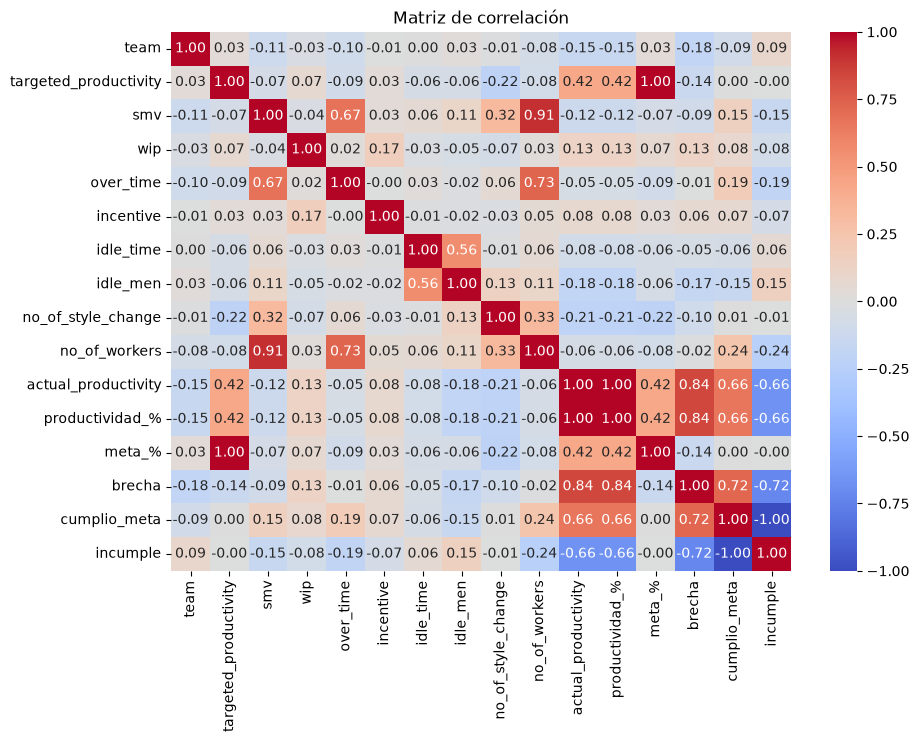

In [35]:
plt.figure(figsize=(10, 7))
sns.heatmap(df_ml.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlación")
plt.show()

874 cumplen (73 %) y 323 no cumplen (27 %).

 hay muchos más que cumplen. Por eso **no basta con el "accuracy"** (porcentaje de aciertos): un modelo que siempre diga "cumple" acertaría el 73 % ¡sin servir para nada! Vamos a fijarnos en el **recall** (cuántos de los que no cumplen logra detectar).



## 3. Preparar los datos para los modelos



In [36]:
# TODO 1: nulos -> quitamos wip
df_ml = df_ml.drop(columns=["wip"], errors="ignore")

# Columnas que no deben entrar como variables de entrada
columnas_fuera = ["date", "actual_productivity", "productividad_%", "meta_%", "brecha", "cumplio_meta"]

# TODO 2: categóricas -> dummies
X = df_ml.drop(columns=columnas_fuera + [TARGET], errors="ignore")
X["team"] = X["team"].astype(str)
X = pd.get_dummies(X, drop_first=True).astype(float)
y = df_ml[TARGET]

print("Nulos en X:", X.isna().sum().sum())
print("Forma de X:", X.shape)
X.head()

Nulos en X: 0
Forma de X: (1197, 29)


,targeted_productivity,smv,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,quarter_Quarter2,quarter_Quarter3,...,team_11,team_12,team_2,team_3,team_4,team_5,team_6,team_7,team_8,team_9
0,0.80,26.16,7080.0,98.0,0.0,0.0,0.0,59.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,0.75,3.94,960.0,0.0,0.0,0.0,0.0,8.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.80,11.41,3660.0,50.0,0.0,0.0,0.0,30.5,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.80,11.41,3660.0,50.0,0.0,0.0,0.0,30.5,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.80,25.90,1920.0,50.0,0.0,0.0,0.0,56.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


In [37]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

# Normalización: fit SOLO en train, transform en train y test
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)
print(X_train_s.shape, X_test_s.shape)

(957, 29) (240, 29)


### Función para calificar los modelos


In [38]:
COSTO_FN, COSTO_FP = 3, 1
resultados = {}   # aquí guardaremos las métricas de cada modelo para compararlos al final

def evaluar(nombre, modelo, Xte=None, yte=None, mostrar=True):
    Xte = X_test_s if Xte is None else Xte
    yte = y_test if yte is None else yte
    pred = modelo.predict(Xte)
    prob = modelo.predict_proba(Xte)[:, 1]
    tn, fp, fn, tp = confusion_matrix(yte, pred).ravel()
    resultados[nombre] = {
        "Accuracy": accuracy_score(yte, pred),
        "Precisión": precision_score(yte, pred, zero_division=0),
        "Recall": recall_score(yte, pred),
        "F1": f1_score(yte, pred),
        "ROC-AUC": roc_auc_score(yte, prob),
        "Costo (3·FN+FP)": COSTO_FN * fn + COSTO_FP * fp,
    }
    print(f"== {nombre} == accuracy = {resultados[nombre]['Accuracy']:.4f} | F1 = {resultados[nombre]['F1']:.4f} | AUC = {resultados[nombre]['ROC-AUC']:.4f}")
    if mostrar:
        print(classification_report(yte, pred, target_names=["Cumple (0)", "Incumple (1)"]))
        sns.heatmap(confusion_matrix(yte, pred), annot=True, fmt="d", cmap="Blues",
                    xticklabels=["Cumple", "Incumple"], yticklabels=["Cumple", "Incumple"])
        plt.title(nombre); plt.xlabel("Predicho"); plt.ylabel("Real"); plt.show()

## 4. Modelos de clasificación
Igual que en el template, cada modelo se entrena **3 veces**:
- **(a) Base:** con la configuración de fábrica.
- **(b) GridSearchCV:** prueba **todas** las combinaciones de "perillas" (hiperparámetros) y se queda con la mejor.
- **(c) RandomizedSearchCV:** prueba combinaciones **al azar** (más rápido).


== NaiveBayes base == accuracy = 0.7208 | F1 = 0.3964 | AUC = 0.6745
              precision    recall  f1-score   support

  Cumple (0)       0.78      0.86      0.82       175
Incumple (1)       0.48      0.34      0.40        65

    accuracy                           0.72       240
   macro avg       0.63      0.60      0.61       240
weighted avg       0.70      0.72      0.70       240



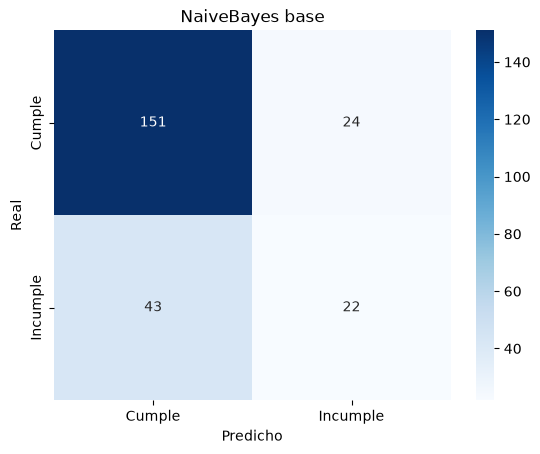

Mejores parámetros: {'var_smoothing': np.float64(1e-12)} | CV score: 0.4405
== NaiveBayes GridSearch == accuracy = 0.7208 | F1 = 0.3964 | AUC = 0.6745
Mejores parámetros: {'var_smoothing': np.float64(0.0001)} | CV score: 0.4405
== NaiveBayes RandomSearch == accuracy = 0.7208 | F1 = 0.3964 | AUC = 0.6745


In [39]:
from sklearn.naive_bayes import GaussianNB

# (a) Base
nb = GaussianNB()
nb.fit(X_train_s, y_train)
evaluar("NaiveBayes base", nb)

# (b) GridSearchCV
param_grid = {"var_smoothing": np.logspace(-12, -3, 10)}
gs = GridSearchCV(GaussianNB(), param_grid, cv=5, scoring="f1", n_jobs=-1)
gs.fit(X_train_s, y_train)
print("Mejores parámetros:", gs.best_params_, "| CV score:", round(gs.best_score_, 4))
evaluar("NaiveBayes GridSearch", gs.best_estimator_, mostrar=False)

# (c) RandomizedSearchCV
rs = RandomizedSearchCV(GaussianNB(), {"var_smoothing": np.logspace(-12, -3, 10)}, n_iter=5,
                        cv=5, scoring="f1", random_state=RANDOM_STATE, n_jobs=-1)
rs.fit(X_train_s, y_train)
print("Mejores parámetros:", rs.best_params_, "| CV score:", round(rs.best_score_, 4))
evaluar("NaiveBayes RandomSearch", rs.best_estimator_, mostrar=False)

 F1 = 0.40 en las 3 versiones: ajustar las perillas no lo mejora. Es de los modelos **más débiles** con estos datos (detecta solo 1 de cada 3 equipos que no cumplen).

### 4.2 Clustering con K-Means


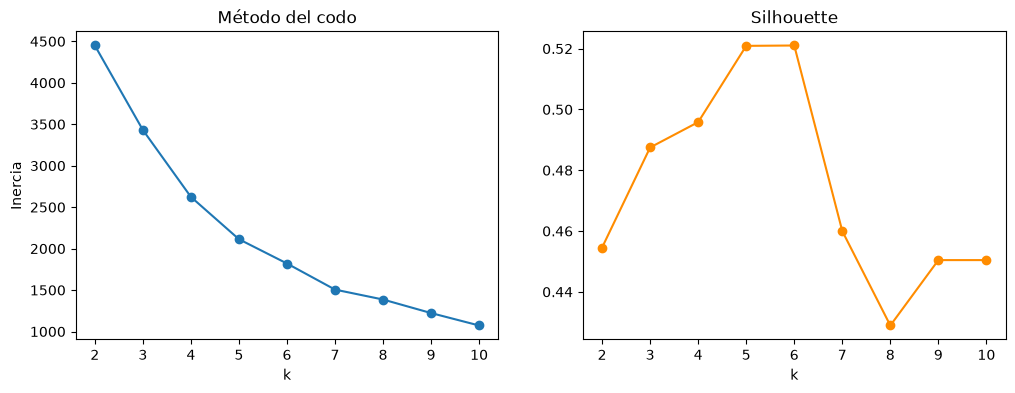

In [40]:
from sklearn.cluster import KMeans

vars_cluster = ["targeted_productivity", "smv", "over_time", "incentive",
                "no_of_workers", "no_of_style_change"]
X_cl = StandardScaler().fit_transform(df_ml[vars_cluster])

# (a) Método del codo: recorre k=2..10, guarda km.inertia_ y grafícalo
inercias, siluetas = [], []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    etiquetas = km.fit_predict(X_cl)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X_cl, etiquetas))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(range(2, 11), inercias, marker="o"); ax[0].set_title("Método del codo"); ax[0].set_xlabel("k"); ax[0].set_ylabel("Inercia")
ax[1].plot(range(2, 11), siluetas, marker="o", color="darkorange"); ax[1].set_title("Silhouette"); ax[1].set_xlabel("k")
plt.show()

In [41]:
# (b) KMeans encuentra el mejor k: grilla de (n_clusters, init, n_init) evaluada con silhouette
filas = []
for k in [2, 3, 4, 5]:
    for init in ["k-means++", "random"]:
        for n_init in [10, 20]:
            km = KMeans(n_clusters=k, init=init, n_init=n_init, random_state=RANDOM_STATE).fit(X_cl)
            filas.append({"k": k, "init": init, "n_init": n_init,
                          "silhouette": round(silhouette_score(X_cl, km.labels_), 3),
                          "tamaños": list(np.bincount(km.labels_))})
pd.DataFrame(filas).sort_values("silhouette", ascending=False).head(10)

,k,init,n_init,silhouette,tamaños
12,5,k-means++,10,0.521,"[139, 545, 434, 69, 10]"
13,5,k-means++,20,0.521,"[139, 545, 434, 69, 10]"
10,4,random,10,0.505,"[464, 10, 147, 576]"
9,4,k-means++,20,0.505,"[576, 464, 147, 10]"
11,4,random,20,0.505,"[464, 10, 147, 576]"
8,4,k-means++,10,0.496,"[584, 464, 147, 2]"
7,3,random,20,0.487,"[147, 464, 586]"
6,3,random,10,0.487,"[147, 464, 586]"
4,3,k-means++,10,0.487,"[464, 586, 147]"
5,3,k-means++,20,0.487,"[464, 586, 147]"


 en la tabla, con 4 o 5 grupos el silhouette sube un poco, **pero aparecen "grupos" de solo 2 a 10 registros** que no sirven para tomar decisiones. Con 3 grupos está el codo de la gráfica y los 3 grupos son grandes y fáciles de explicar.

In [42]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE)
df_ml["cluster"] = kmeans.fit_predict(X_cl)

print("adjusted_rand_score (clusters vs. incumple):", round(adjusted_rand_score(y, df_ml["cluster"]), 3))

perfil = df_ml.groupby("cluster")[vars_cluster + ["actual_productivity"]].mean().round(2)
perfil["% cumple meta"] = ((1 - df_ml.groupby("cluster")[TARGET].mean()) * 100).round(1)
perfil["registros"] = df_ml["cluster"].value_counts().sort_index()
display(perfil)
display(pd.crosstab(df_ml["cluster"], df_ml["department"]))

adjusted_rand_score (clusters vs. incumple): 0.009


,targeted_productivity,smv,over_time,incentive,no_of_workers,no_of_style_change,actual_productivity,% cumple meta,registros
cluster,,,,,,,,,
0,0.73,24.01,7532.72,49.38,54.57,0.00,0.74,83.0,464
1,0.74,5.38,2059.23,32.61,13.72,0.00,0.76,65.4,586
2,0.67,25.41,5206.53,25.27,54.90,1.22,0.63,72.1,147


department,finishing,sewing
cluster,,
0,6,458
1,500,86
2,0,147


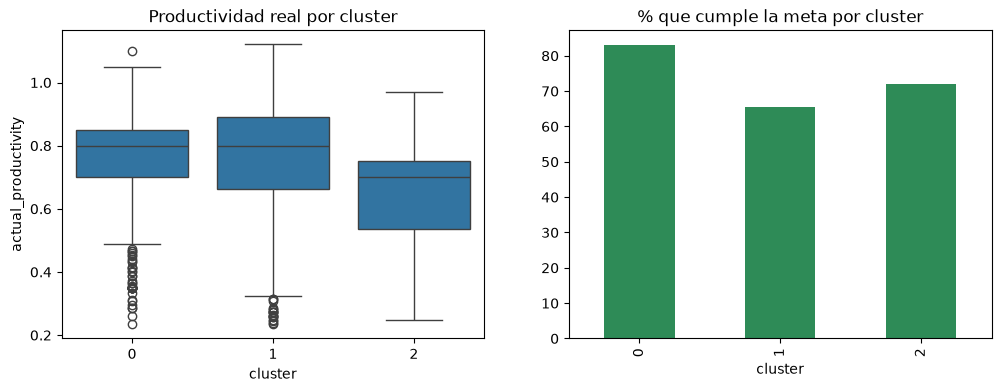

In [43]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df_ml, x="cluster", y="actual_productivity", ax=ax[0])
ax[0].set_title("Productividad real por cluster")
perfil["% cumple meta"].plot(kind="bar", ax=ax[1], color="seagreen")
ax[1].set_title("% que cumple la meta por cluster")
plt.show()

**Los 3 grupos que encontró K-Means:**

| Grupo | Nombre | Cómo es | ¿Cómo le va? |
|---|---|---|---|
| 0 | **Costura estable** | Costura, equipos grandes (~55 personas), sin cambios de estilo | **83 % cumple** (el mejor) |
| 1 | **Acabado / equipos pequeños** | Casi todo acabado, ~14 personas, tareas cortas | Solo **65 % cumple** (el más inestable) |
| 2 | **Costura con cambio de estilo** | Costura, siempre con cambio de prenda | **Productividad más baja (0.63)** |

confirma **H1** (los cambios de estilo bajan la productividad) y **H3** (acabado es más inestable).
El `adjusted_rand_score` ≈ 0 solo quiere decir que los grupos son **tipos de trabajo**, no "los que cumplen vs. los que no".

### 4.2.b Otros algoritmos de clustering 
  Probamos también: **Jerárquico** (con dendrograma), **DBSCAN** y **GMM**.


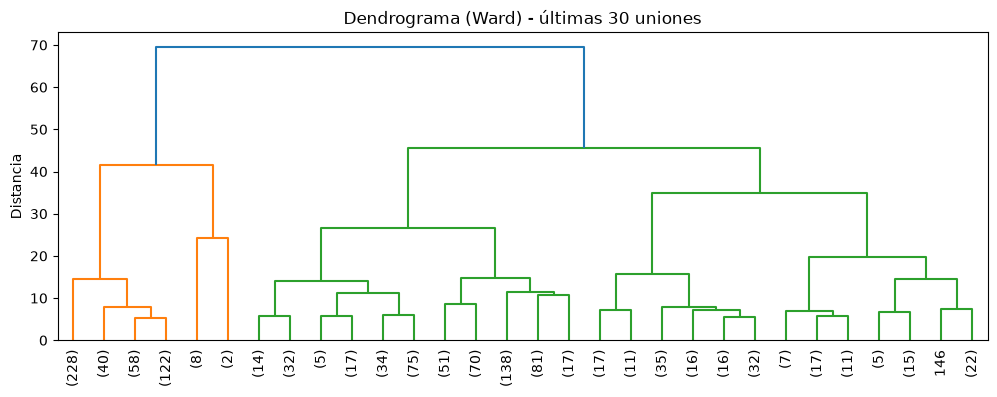

In [44]:
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import linkage, dendrogram

# --- Jerárquico aglomerativo: dendrograma (método de Ward) ---
Z = linkage(X_cl, method="ward")
plt.figure(figsize=(12, 4))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90)
plt.title("Dendrograma (Ward) - últimas 30 uniones"); plt.ylabel("Distancia"); plt.show()

 es como un "árbol genealógico" de los grupos. Mientras más alta la unión, más diferentes son los grupos que se unen. El salto más alto separa **acabado vs. costura** (2 grupos) y el siguiente da **3 grupos**.

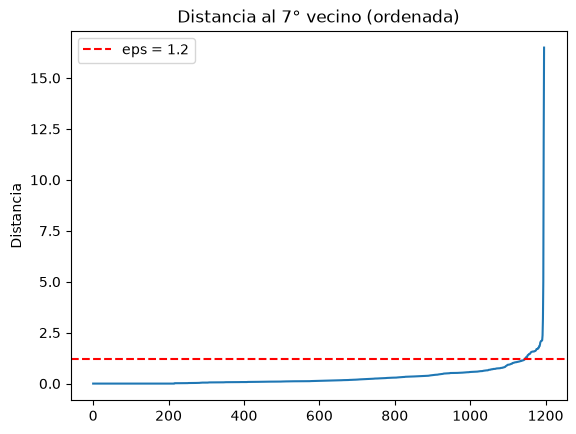

In [45]:
# --- DBSCAN: elegir eps con la gráfica de distancia al k-ésimo vecino (MinPts = D + 1 = 7) ---
min_pts = X_cl.shape[1] + 1
distancias, _ = NearestNeighbors(n_neighbors=min_pts).fit(X_cl).kneighbors(X_cl)
plt.plot(np.sort(distancias[:, -1]))
plt.axhline(1.2, linestyle="--", color="red", label="eps = 1.2")
plt.title(f"Distancia al {min_pts}° vecino (ordenada)"); plt.ylabel("Distancia"); plt.legend(); plt.show()

 **Para elegir eps de DBSCAN:** buscamos donde la curva "se dispara" (el codo). Tomamos **eps = 1.2**.

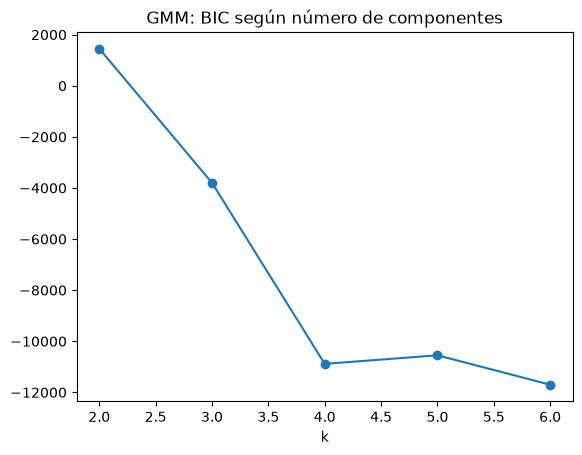

In [46]:
# --- GMM: elegir el número de componentes con el BIC (menor es mejor) ---
bics = [GaussianMixture(n_components=k, n_init=3, random_state=RANDOM_STATE).fit(X_cl).bic(X_cl) for k in range(2, 7)]
plt.plot(range(2, 7), bics, marker="o"); plt.title("GMM: BIC según número de componentes"); plt.xlabel("k"); plt.show()

 **BIC:** mientras más bajo, mejor. El mínimo está en **4 grupos**.

In [47]:
# --- Tabla comparativa ---
etiquetas_alg = {
    "K-Means (k=3)": df_ml["cluster"].values,
    "Jerárquico Ward (k=3)": AgglomerativeClustering(n_clusters=3, linkage="ward").fit_predict(X_cl),
    "Jerárquico Complete (k=3)": AgglomerativeClustering(n_clusters=3, linkage="complete").fit_predict(X_cl),
    "DBSCAN (eps=1.2, MinPts=7)": DBSCAN(eps=1.2, min_samples=min_pts).fit_predict(X_cl),
    "GMM (k=4)": GaussianMixture(n_components=4, n_init=3, random_state=RANDOM_STATE).fit(X_cl).predict(X_cl),
}
filas = []
for nombre, et in etiquetas_alg.items():
    mascara = et != -1                       # en DBSCAN, -1 = ruido
    grupos = pd.Series(et[mascara]).value_counts().sort_index().tolist()
    filas.append({"Algoritmo": nombre, "Nº clusters": len(grupos), "Ruido": int((~mascara).sum()),
                  "Silhouette": round(silhouette_score(X_cl[mascara], et[mascara]), 3),
                  "Tamaños": grupos if len(grupos) <= 6 else f"{grupos[:6]}..."})
pd.DataFrame(filas).set_index("Algoritmo")

,Nº clusters,Ruido,Silhouette,Tamaños
Algoritmo,,,,
K-Means (k=3),3,0,0.487,"[464, 586, 147]"
Jerárquico Ward (k=3),3,0,0.460,"[458, 205, 534]"
Jerárquico Complete (k=3),3,0,0.614,"[1187, 2, 8]"
"DBSCAN (eps=1.2, MinPts=7)",6,27,0.316,"[1014, 11, 8, 108, 12, 17]"
GMM (k=4),4,0,0.444,"[134, 486, 151, 426]"


**Comparación:**

| Algoritmo | Resultado | ¿Sirve? |
|---|---|---|
| **K-Means** | 3 grupos grandes (silhouette 0.49) |  **El elegido** |
| Jerárquico Ward | Grupos parecidos (silhouette 0.46). El dendrograma también muestra 2–3 grupos claros |  Similar |
| Jerárquico Complete | Silhouette alto (0.61) **pero engañoso**: 1187 en un grupo y grupos de 2 y 8 | no |
| DBSCAN | Un grupo gigante de 1014, grupos diminutos y 27 de "ruido" |  No sirve con estos datos |
| GMM | 4 grupos, más difíciles de explicar | no |

 ** K-Means:** da grupos **grandes, claros y fáciles de explicar al jefe de planta**.

### 4.3 PCA (Análisis de Componentes Principales)




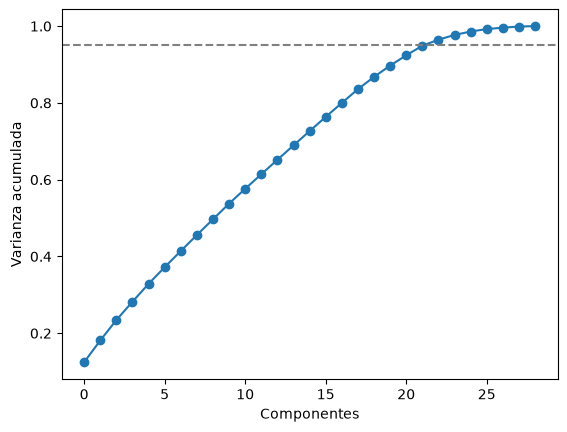

Variables originales: 29 | componentes para explicar más del 95 %: 23


In [48]:
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Varianza explicada
pca = PCA().fit(X_train_s)
plt.plot(np.cumsum(pca.explained_variance_ratio_), marker="o")
plt.axhline(0.95, linestyle="--", color="gray")
plt.xlabel("Componentes"); plt.ylabel("Varianza acumulada"); plt.show()

n_95 = np.argmax(np.cumsum(pca.explained_variance_ratio_) >= 0.95) + 1
print(f"Variables originales: {X.shape[1]} | componentes para explicar más del 95 %: {n_95}")

In [49]:
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Aplica la clasificación (por cada modelo visto en clase) con y sin PCA, compara resultados
modelos_pca = {
    "NaiveBayes": GaussianNB(),
    "LogReg": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
    "Árbol": DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE),
    "RandomForest": RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE),
}
comparacion_pca = []
for nombre, modelo in modelos_pca.items():
    sin_pca = modelo.fit(X_train_s, y_train)
    f1_sin = f1_score(y_test, sin_pca.predict(X_test_s))
    con_pca = Pipeline([("pca", PCA(n_components=0.95, random_state=RANDOM_STATE)), ("modelo", modelo)])
    con_pca.fit(X_train_s, y_train)
    f1_con = f1_score(y_test, con_pca.predict(X_test_s))
    comparacion_pca.append({"Modelo": nombre, "F1 sin PCA": round(f1_sin, 3), "F1 con PCA": round(f1_con, 3)})

pd.DataFrame(comparacion_pca).set_index("Modelo")

,F1 sin PCA,F1 con PCA
Modelo,,
NaiveBayes,0.396,0.217
LogReg,0.512,0.482
Árbol,0.514,0.420
RandomForest,0.703,0.479


 todos los modelos **empeoran con PCA** (por ejemplo, Random Forest baja de 0.70 a 0.48). Se necesitan 23 de 29 componentes para guardar el 95 %, así que casi no resume nada y se pierde información útil.

### PCA 
Con las 29 columnas es difícil interpretar, así que aplicamos PCA a las **8 variables numéricas** de operación.
Los **loadings** (mapa de colores) dicen **cuánto pesa cada variable en cada componente**: colores fuertes = pesa mucho.

Varianza acumulada (%): [ 33.8  53.3  67.4  79.8  90.1  95.4  99.  100. ]


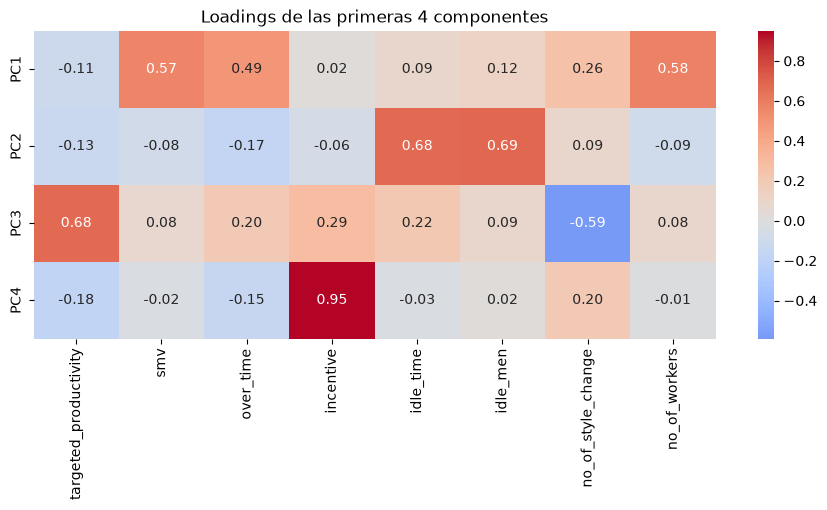

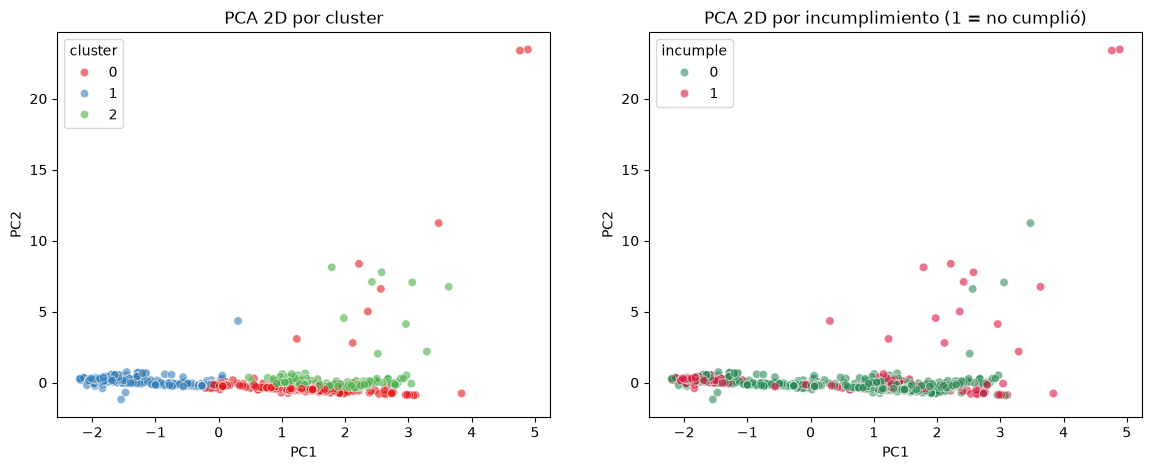

In [50]:
vars_pca = ["targeted_productivity", "smv", "over_time", "incentive",
            "idle_time", "idle_men", "no_of_style_change", "no_of_workers"]
X_num = StandardScaler().fit_transform(df_ml[vars_pca])
pca_num = PCA().fit(X_num)
print("Varianza acumulada (%):", (np.cumsum(pca_num.explained_variance_ratio_) * 100).round(1))

loadings = pd.DataFrame(pca_num.components_[:4], columns=vars_pca, index=["PC1", "PC2", "PC3", "PC4"])
plt.figure(figsize=(11, 4))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Loadings de las primeras 4 componentes"); plt.show()

X_2d = PCA(n_components=2).fit_transform(X_num)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x=X_2d[:, 0], y=X_2d[:, 1], hue=df_ml["cluster"], palette="Set1", alpha=0.6, ax=ax[0])
ax[0].set_title("PCA 2D por cluster")
sns.scatterplot(x=X_2d[:, 0], y=X_2d[:, 1], hue=y, palette={0: "seagreen", 1: "crimson"}, alpha=0.6, ax=ax[1])
ax[1].set_title("PCA 2D por incumplimiento (1 = no cumplió)")
for a in ax: a.set_xlabel("PC1"); a.set_ylabel("PC2")
plt.show()


- Para clasificar se necesitan **23 de 29** componentes: casi no se resume nada.
- **Con PCA los modelos empeoran** (Random Forest: F1 de 0.70 a 0.48).
- Con las 8 variables numéricas, **5 componentes guardan el 90 %** de la información.


- **PC1 = tamaño de la operación** (trabajadores, SMV, horas extra)
- **PC2 = paros** (tiempo y trabajadores parados)
- **PC3 = meta vs. cambios de estilo**
- **PC4 = incentivo**

 **Conclusión:** PCA **sirve para dibujar** (en la gráfica 2D los 3 grupos se ven separados), pero **no para mejorar los modelos**. En la gráfica de la derecha los que no cumplen (rojo) están mezclados: hace falta un clasificador.

### 4.4 LDA (Análisis Discriminante Lineal)


== LDA base == accuracy = 0.7708 | F1 = 0.4554 | AUC = 0.7464
              precision    recall  f1-score   support

  Cumple (0)       0.79      0.93      0.85       175
Incumple (1)       0.64      0.35      0.46        65

    accuracy                           0.77       240
   macro avg       0.72      0.64      0.66       240
weighted avg       0.75      0.77      0.75       240



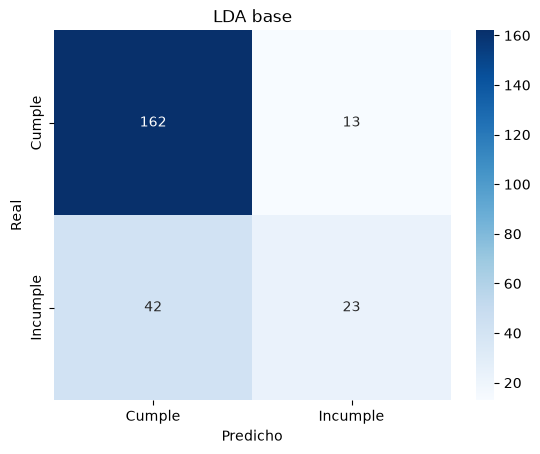

Mejores parámetros: {'shrinkage': 0.9, 'solver': 'lsqr'} | CV score: 0.48
== LDA GridSearch == accuracy = 0.7125 | F1 = 0.4889 | AUC = 0.7045
Mejores parámetros: {'shrinkage': np.float64(0.9507143064099162)} | CV score: 0.4883
== LDA RandomSearch == accuracy = 0.7208 | F1 = 0.5248 | AUC = 0.7009


In [51]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# (a) Base
lda = LinearDiscriminantAnalysis()
lda.fit(X_train_s, y_train)
evaluar("LDA base", lda)

# (b) GridSearchCV
param_grid_lda = [{"solver": ["svd"]},
                  {"solver": ["lsqr", "eigen"], "shrinkage": [None, "auto", 0.1, 0.5, 0.9]}]
gs_lda = GridSearchCV(LinearDiscriminantAnalysis(), param_grid_lda, cv=5, scoring="f1", n_jobs=-1)
gs_lda.fit(X_train_s, y_train)
print("Mejores parámetros:", gs_lda.best_params_, "| CV score:", round(gs_lda.best_score_, 4))
evaluar("LDA GridSearch", gs_lda.best_estimator_, mostrar=False)

# (c) RandomizedSearchCV
rs_lda = RandomizedSearchCV(LinearDiscriminantAnalysis(solver="lsqr"), {"shrinkage": uniform(0, 1)},
                            n_iter=10, cv=5, scoring="f1", random_state=RANDOM_STATE, n_jobs=-1)
rs_lda.fit(X_train_s, y_train)
print("Mejores parámetros:", rs_lda.best_params_, "| CV score:", round(rs_lda.best_score_, 4))
evaluar("LDA RandomSearch", rs_lda.best_estimator_, mostrar=False)

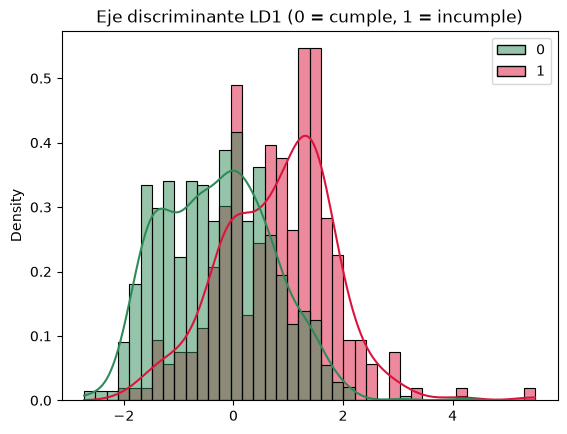

Variables que más pesan en LD1 (+ empuja a 'incumple', - a 'cumple'):
smv                  1.218
no_of_workers       -1.003
department_sewing   -0.814
team_8               0.406
team_11              0.381
team_7               0.380
team_6               0.347
idle_men             0.316
day_Thursday         0.309
team_10              0.256
dtype: float64


In [52]:
# LDA como reducción ANTES de clasificar: de 29 columnas a 1 eje (LD1)
lda_red = LinearDiscriminantAnalysis(n_components=1)
X_train_lda = lda_red.fit_transform(X_train_s, y_train)
X_test_lda = lda_red.transform(X_test_s)

sns.histplot(x=X_train_lda[:, 0], hue=y_train.values, bins=40, kde=True, stat="density",
             common_norm=False, palette={0: "seagreen", 1: "crimson"})
plt.title("Eje discriminante LD1 (0 = cumple, 1 = incumple)"); plt.show()

coef = pd.Series(lda_red.scalings_[:, 0], index=X.columns)
print("Variables que más pesan en LD1 (+ empuja a 'incumple', - a 'cumple'):")
print(coef.reindex(coef.abs().sort_values(ascending=False).index).head(10).round(3))

In [53]:
from sklearn.neighbors import KNeighborsClassifier

# Comparación de la métrica CON y SIN LDA
evaluar("LogReg SIN LDA", LogisticRegression(max_iter=2000, class_weight="balanced").fit(X_train_s, y_train), mostrar=False)
evaluar("LogReg CON LDA", LogisticRegression(max_iter=2000, class_weight="balanced").fit(X_train_lda, y_train),
        Xte=X_test_lda, mostrar=False)
evaluar("kNN SIN LDA", KNeighborsClassifier(n_neighbors=15).fit(X_train_s, y_train), mostrar=False)
evaluar("kNN CON LDA", KNeighborsClassifier(n_neighbors=15).fit(X_train_lda, y_train), Xte=X_test_lda, mostrar=False)

== LogReg SIN LDA == accuracy = 0.6750 | F1 = 0.5125 | AUC = 0.7499
== LogReg CON LDA == accuracy = 0.6958 | F1 = 0.5350 | AUC = 0.7464
== kNN SIN LDA == accuracy = 0.7542 | F1 = 0.3516 | AUC = 0.6918
== kNN CON LDA == accuracy = 0.7708 | F1 = 0.4860 | AUC = 0.7127



- Las dos "montañas" (verde = cumple, roja = no cumple) están corridas pero **se enciman**: una línea recta no las separa bien.
- **Con LDA el kNN mejora** (F1 de 0.35 a 0.49) y la regresión logística un poco (0.51 a 0.54).

 **Qué empuja hacia "no cumple"** (pesos +): tareas más complejas (**SMV**) y los **equipos 6, 7, 8, 10 y 11**.
**Qué empuja hacia "cumple"** (pesos −): **más trabajadores** y ser de **costura**.
 Confirma **H2**: hay equipos que rinden peor de forma constante (los mismos del EDA).

### 4.5 Árbol de decisión


== Árbol base == accuracy = 0.7417 | F1 = 0.4918 | AUC = 0.6536
              precision    recall  f1-score   support

  Cumple (0)       0.81      0.85      0.83       175
Incumple (1)       0.53      0.46      0.49        65

    accuracy                           0.74       240
   macro avg       0.67      0.65      0.66       240
weighted avg       0.73      0.74      0.74       240



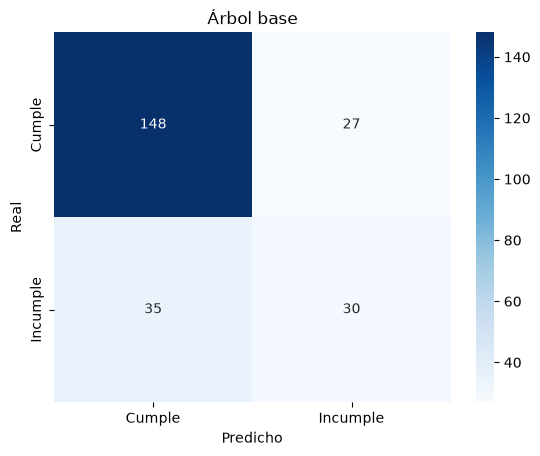

Mejores parámetros: {'class_weight': None, 'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 5, 'min_samples_split': 2} | CV score: 0.6317
== Árbol GridSearch == accuracy = 0.8125 | F1 = 0.6087 | AUC = 0.8254
Mejores parámetros: {'class_weight': None, 'criterion': 'gini', 'max_depth': 14, 'min_samples_leaf': 1, 'min_samples_split': 26} | CV score: 0.6347
== Árbol RandomSearch == accuracy = 0.8458 | F1 = 0.6838 | AUC = 0.8268


In [54]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

# (a) Base
arbol = DecisionTreeClassifier(random_state=RANDOM_STATE)
arbol.fit(X_train_s, y_train)
evaluar("Árbol base", arbol)

# (b) GridSearchCV
param_grid_arbol = {"max_depth": [3, 4, 5, 6, 8, None], "min_samples_split": [2, 10],
                    "min_samples_leaf": [1, 5, 10], "criterion": ["gini", "entropy"],
                    "class_weight": [None, "balanced"]}
gs_arbol = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE), param_grid_arbol,
                        cv=5, scoring="f1", n_jobs=-1)
gs_arbol.fit(X_train_s, y_train)
print("Mejores parámetros:", gs_arbol.best_params_, "| CV score:", round(gs_arbol.best_score_, 4))
evaluar("Árbol GridSearch", gs_arbol.best_estimator_, mostrar=False)

# (c) RandomizedSearchCV
param_dist_arbol = {"max_depth": randint(2, 15), "min_samples_split": randint(2, 30),
                    "min_samples_leaf": randint(1, 20), "criterion": ["gini", "entropy"],
                    "class_weight": [None, "balanced"]}
rs_arbol = RandomizedSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE), param_dist_arbol,
                              n_iter=30, cv=5, scoring="f1", random_state=RANDOM_STATE, n_jobs=-1)
rs_arbol.fit(X_train_s, y_train)
print("Mejores parámetros:", rs_arbol.best_params_, "| CV score:", round(rs_arbol.best_score_, 4))
evaluar("Árbol RandomSearch", rs_arbol.best_estimator_, mostrar=False)

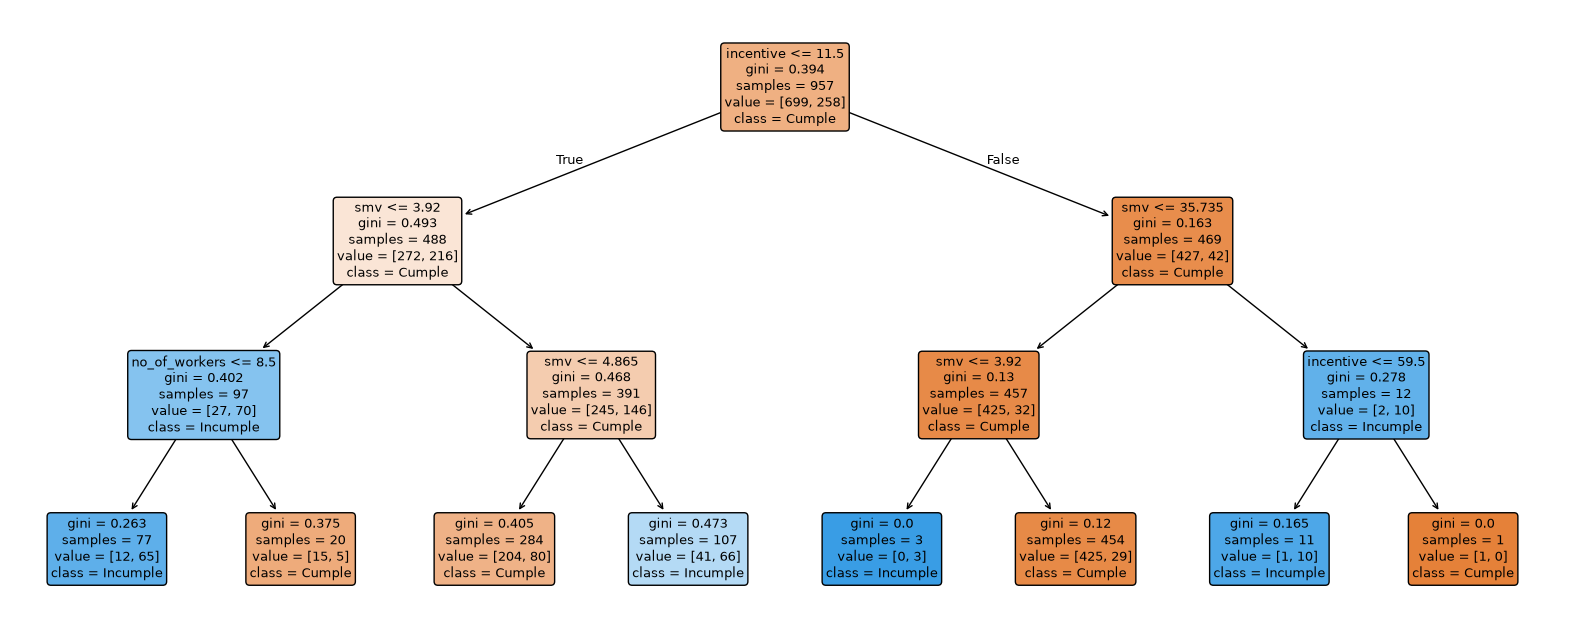

In [55]:
# (extra) Árbol de 3 niveles, entrenado con los datos SIN escalar para que las reglas se lean en unidades reales
arbol_vis = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE).fit(X_train, y_train)
plt.figure(figsize=(20, 8))
plot_tree(arbol_vis, feature_names=X.columns, class_names=["Cumple", "Incumple"], filled=True, rounded=True, fontsize=9)
plt.show()

 cada cuadro es una pregunta. `samples` = cuántos registros llegan ahí; `value = [cumplen, no cumplen]`.

**El hallazgo más importante del proyecto:** la primera pregunta es **"¿el incentivo es ≤ 11.5?"**
- **Sin incentivo:** no cumplen **216 de 488** → **44 %**
- **Con incentivo:** no cumplen **42 de 469** → solo **9 %**

 Confirma **H4**: el incentivo es la palanca más fuerte para cumplir la meta.

### 4.6 Random Forest


== RandomForest base == accuracy = 0.8083 | F1 = 0.5893 | AUC = 0.8438
              precision    recall  f1-score   support

  Cumple (0)       0.83      0.92      0.88       175
Incumple (1)       0.70      0.51      0.59        65

    accuracy                           0.81       240
   macro avg       0.77      0.71      0.73       240
weighted avg       0.80      0.81      0.80       240



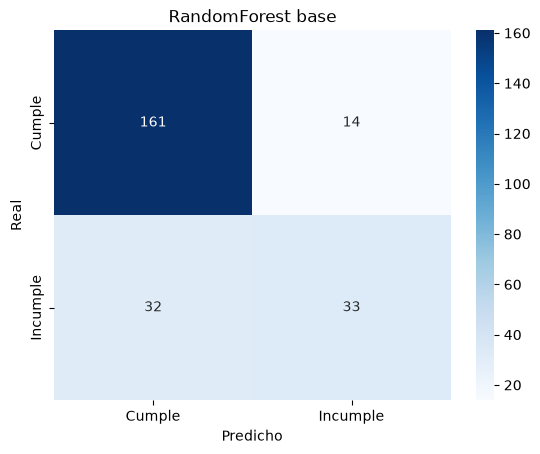

Mejores parámetros: {'class_weight': 'balanced', 'max_depth': None, 'max_features': 0.5, 'n_estimators': 300} | CV score: 0.6714
== RandomForest GridSearch == accuracy = 0.8292 | F1 = 0.6870 | AUC = 0.8402
              precision    recall  f1-score   support

  Cumple (0)       0.89      0.88      0.88       175
Incumple (1)       0.68      0.69      0.69        65

    accuracy                           0.83       240
   macro avg       0.78      0.79      0.78       240
weighted avg       0.83      0.83      0.83       240



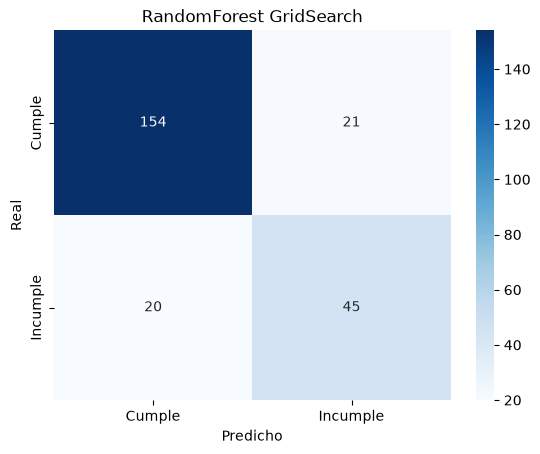

Mejores parámetros: {'class_weight': 'balanced', 'max_depth': 17, 'max_features': 0.5, 'n_estimators': 224} | CV score: 0.6762
== RandomForest RandomSearch == accuracy = 0.8208 | F1 = 0.6718 | AUC = 0.8425


In [56]:
from sklearn.ensemble import RandomForestClassifier

# (a) Base
rf = RandomForestClassifier(random_state=RANDOM_STATE)
rf.fit(X_train_s, y_train)
evaluar("RandomForest base", rf)

# (b) GridSearchCV
param_grid_rf = {"n_estimators": [100, 300], "max_depth": [None, 5, 10],
                 "max_features": ["sqrt", 0.5], "class_weight": [None, "balanced"]}
gs_rf = GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE), param_grid_rf, cv=5, scoring="f1", n_jobs=-1)
gs_rf.fit(X_train_s, y_train)
print("Mejores parámetros:", gs_rf.best_params_, "| CV score:", round(gs_rf.best_score_, 4))
evaluar("RandomForest GridSearch", gs_rf.best_estimator_)

# (c) RandomizedSearchCV
param_dist_rf = {"n_estimators": randint(50, 400), "max_depth": randint(3, 20),
                 "max_features": ["sqrt", 0.5], "class_weight": [None, "balanced"]}
rs_rf = RandomizedSearchCV(RandomForestClassifier(random_state=RANDOM_STATE), param_dist_rf,
                           n_iter=20, cv=5, scoring="f1", random_state=RANDOM_STATE, n_jobs=-1)
rs_rf.fit(X_train_s, y_train)
print("Mejores parámetros:", rs_rf.best_params_, "| CV score:", round(rs_rf.best_score_, 4))
evaluar("RandomForest RandomSearch", rs_rf.best_estimator_, mostrar=False)

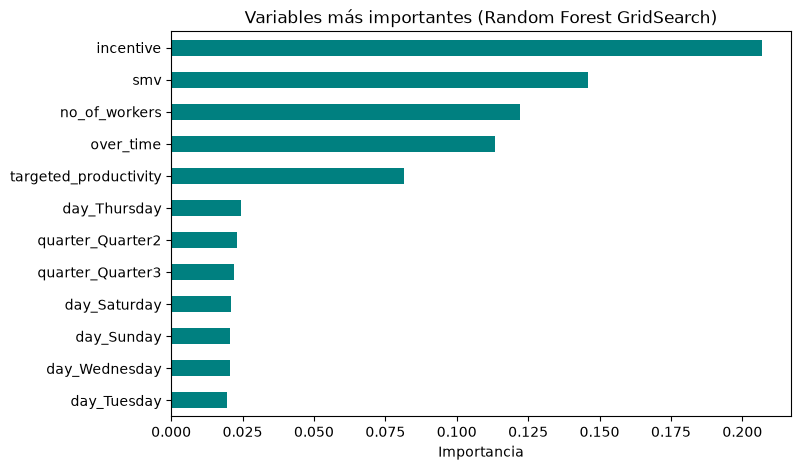

In [57]:
# (extra) feature_importances_
importancias = pd.Series(gs_rf.best_estimator_.feature_importances_, index=X.columns).sort_values()
importancias.tail(12).plot(kind="barh", figsize=(8, 5), color="teal")
plt.title("Variables más importantes (Random Forest GridSearch)"); plt.xlabel("Importancia"); plt.show()

 es el **mejor modelo** (F1 0.69, el menor costo). Las variables que más usa: **incentivo, SMV, número de trabajadores, horas extra y meta**.

 todas son cosas que **la gerencia planea y puede cambiar**.

### 4.7 AdaBoost


In [58]:
from sklearn.ensemble import AdaBoostClassifier

base_arbol = DecisionTreeClassifier(max_depth=2, random_state=RANDOM_STATE)

# (a) Base
ada = AdaBoostClassifier(estimator=base_arbol, random_state=RANDOM_STATE)
ada.fit(X_train_s, y_train)
evaluar("AdaBoost base", ada, mostrar=False)

# (b) GridSearchCV
param_grid_ada = {"n_estimators": [50, 100, 200], "learning_rate": [0.05, 0.1, 0.5, 1.0],
                  "estimator": [DecisionTreeClassifier(max_depth=1), DecisionTreeClassifier(max_depth=2),
                                DecisionTreeClassifier(max_depth=3)]}
gs_ada = GridSearchCV(AdaBoostClassifier(random_state=RANDOM_STATE), param_grid_ada, cv=5, scoring="f1", n_jobs=-1)
gs_ada.fit(X_train_s, y_train)
print("Mejores parámetros:", gs_ada.best_params_, "| CV score:", round(gs_ada.best_score_, 4))
evaluar("AdaBoost GridSearch", gs_ada.best_estimator_, mostrar=False)

# (c) RandomizedSearchCV
param_dist_ada = {"n_estimators": randint(50, 300), "learning_rate": loguniform(0.01, 1.0)}
rs_ada = RandomizedSearchCV(AdaBoostClassifier(estimator=base_arbol, random_state=RANDOM_STATE), param_dist_ada,
                            n_iter=15, cv=5, scoring="f1", random_state=RANDOM_STATE, n_jobs=-1)
rs_ada.fit(X_train_s, y_train)
print("Mejores parámetros:", rs_ada.best_params_, "| CV score:", round(rs_ada.best_score_, 4))
evaluar("AdaBoost RandomSearch", rs_ada.best_estimator_, mostrar=False)

== AdaBoost base == accuracy = 0.8167 | F1 = 0.6271 | AUC = 0.8317
Mejores parámetros: {'estimator': DecisionTreeClassifier(max_depth=2), 'learning_rate': 1.0, 'n_estimators': 200} | CV score: 0.6151
== AdaBoost GridSearch == accuracy = 0.8208 | F1 = 0.6325 | AUC = 0.8293
Mejores parámetros: {'learning_rate': np.float64(0.2607024758370766), 'n_estimators': 199} | CV score: 0.5521
== AdaBoost RandomSearch == accuracy = 0.7958 | F1 = 0.5664 | AUC = 0.8263


 F1 ≈ 0.63 con GridSearch. Bueno, pero por debajo de Random Forest.

### 4.8 XGBoost


== XGBoost base == accuracy = 0.8083 | F1 = 0.6102 | AUC = 0.8301
Mejores parámetros: {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 300, 'scale_pos_weight': np.float64(2.7093023255813953), 'subsample': 0.8} | CV score: 0.6611
== XGBoost GridSearch == accuracy = 0.8250 | F1 = 0.6769 | AUC = 0.8337
              precision    recall  f1-score   support

  Cumple (0)       0.88      0.88      0.88       175
Incumple (1)       0.68      0.68      0.68        65

    accuracy                           0.82       240
   macro avg       0.78      0.78      0.78       240
weighted avg       0.82      0.82      0.82       240



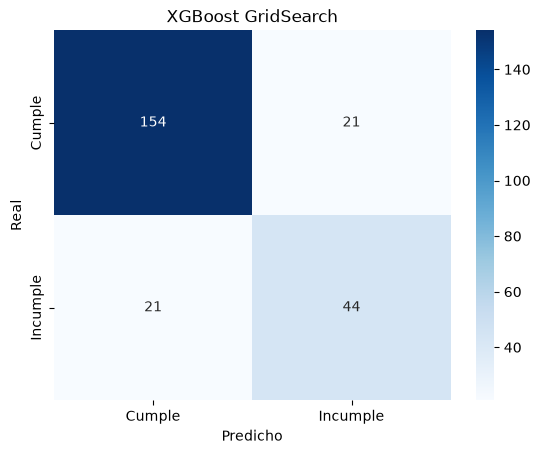

Mejores parámetros: {'colsample_bytree': np.float64(0.6254233401144095), 'learning_rate': np.float64(0.028797752657070342), 'max_depth': 6, 'n_estimators': 198, 'scale_pos_weight': np.float64(2.7093023255813953), 'subsample': np.float64(0.8550229885420852)} | CV score: 0.6598
== XGBoost RandomSearch == accuracy = 0.7958 | F1 = 0.6475 | AUC = 0.8295


In [59]:
from xgboost import XGBClassifier

peso = (y_train == 0).sum() / (y_train == 1).sum()   # equivalente a "balanced" en XGBoost

# (a) Base
xgb = XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE)
xgb.fit(X_train_s, y_train)
evaluar("XGBoost base", xgb, mostrar=False)

# (b) GridSearchCV
param_grid_xgb = {"n_estimators": [100, 300], "learning_rate": [0.05, 0.1], "max_depth": [3, 5],
                  "subsample": [0.8, 1.0], "scale_pos_weight": [1, peso]}
gs_xgb = GridSearchCV(XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE), param_grid_xgb,
                      cv=5, scoring="f1", n_jobs=-1)
gs_xgb.fit(X_train_s, y_train)
print("Mejores parámetros:", gs_xgb.best_params_, "| CV score:", round(gs_xgb.best_score_, 4))
evaluar("XGBoost GridSearch", gs_xgb.best_estimator_)

# (c) RandomizedSearchCV
param_dist_xgb = {"n_estimators": randint(100, 500), "learning_rate": loguniform(0.01, 0.3),
                  "max_depth": randint(2, 8), "subsample": uniform(0.6, 0.4),
                  "colsample_bytree": uniform(0.6, 0.4), "scale_pos_weight": [1, peso]}
rs_xgb = RandomizedSearchCV(XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE), param_dist_xgb,
                            n_iter=20, cv=5, scoring="f1", random_state=RANDOM_STATE, n_jobs=-1)
rs_xgb.fit(X_train_s, y_train)
print("Mejores parámetros:", rs_xgb.best_params_, "| CV score:", round(rs_xgb.best_score_, 4))
evaluar("XGBoost RandomSearch", rs_xgb.best_estimator_, mostrar=False)

 F1 ≈ 0.68 con GridSearch: **casi empatado con Random Forest**, pero es más difícil de explicar.

### 4.9 SVM (Máquinas de Soporte Vectorial)


== SVM base == accuracy = 0.7667 | F1 = 0.3778 | AUC = 0.7124
Mejores parámetros: {'C': 10, 'class_weight': 'balanced', 'gamma': 0.01, 'kernel': 'rbf'} | CV score: 0.5529
== SVM GridSearch == accuracy = 0.6833 | F1 = 0.5000 | AUC = 0.7591
              precision    recall  f1-score   support

  Cumple (0)       0.82      0.72      0.77       175
Incumple (1)       0.44      0.58      0.50        65

    accuracy                           0.68       240
   macro avg       0.63      0.65      0.63       240
weighted avg       0.72      0.68      0.70       240



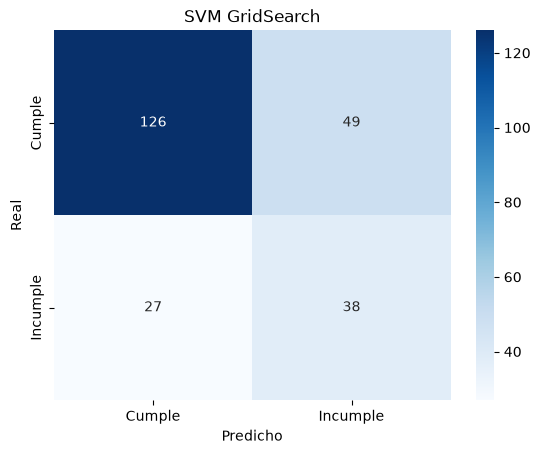

Mejores parámetros: {'C': np.float64(56.78201970293127), 'class_weight': 'balanced', 'gamma': np.float64(0.0035113563139704067)} | CV score: 0.5395
== SVM RandomSearch == accuracy = 0.7083 | F1 = 0.5455 | AUC = 0.7605


In [60]:
from sklearn.svm import SVC

# (a) Base (probability=True para poder calcular el ROC-AUC)
svm = SVC(probability=True, random_state=RANDOM_STATE)
svm.fit(X_train_s, y_train)
evaluar("SVM base", svm, mostrar=False)

# (b) GridSearchCV
param_grid_svm = {"kernel": ["linear", "rbf"], "C": [0.1, 1, 10], "gamma": ["scale", 0.01, 0.1],
                  "class_weight": [None, "balanced"]}
gs_svm = GridSearchCV(SVC(probability=True, random_state=RANDOM_STATE), param_grid_svm, cv=5, scoring="f1", n_jobs=-1)
gs_svm.fit(X_train_s, y_train)
print("Mejores parámetros:", gs_svm.best_params_, "| CV score:", round(gs_svm.best_score_, 4))
evaluar("SVM GridSearch", gs_svm.best_estimator_)

# (c) RandomizedSearchCV
param_dist_svm = {"C": loguniform(0.01, 100), "gamma": loguniform(0.001, 1), "class_weight": [None, "balanced"]}
rs_svm = RandomizedSearchCV(SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE), param_dist_svm,
                            n_iter=15, cv=5, scoring="f1", random_state=RANDOM_STATE, n_jobs=-1)
rs_svm.fit(X_train_s, y_train)
print("Mejores parámetros:", rs_svm.best_params_, "| CV score:", round(rs_svm.best_score_, 4))
evaluar("SVM RandomSearch", rs_svm.best_estimator_, mostrar=False)

 F1 ≈ 0.50–0.55. Nivel medio: mejor que Naive Bayes y LDA, pero por debajo de los modelos de árboles.

## 5. Regresión: ¿cuánto va a producir el equipo?




In [61]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor
from xgboost import XGBRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error

TARGET_REG = "actual_productivity"
y_r = df_ml[TARGET_REG]

# Split y normalización (fit SOLO en train). Mismas X de la clasificación.
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X, y_r, test_size=0.2, random_state=RANDOM_STATE)
scaler_r = StandardScaler()
Xr_train_s = scaler_r.fit_transform(Xr_train)
Xr_test_s = scaler_r.transform(Xr_test)

resultados_reg = {}
def evaluar_reg(nombre, modelo):
    pred = modelo.predict(Xr_test_s)
    resultados_reg[nombre] = {"MAE": mean_absolute_error(yr_test, pred),
                              "RMSE": np.sqrt(mean_squared_error(yr_test, pred)),
                              "R2": r2_score(yr_test, pred)}
    r = resultados_reg[nombre]
    print(f"{nombre}: MAE = {r['MAE']:.4f} | RMSE = {r['RMSE']:.4f} | R2 = {r['R2']:.4f}")

# Modelo base: siempre predice el promedio (cualquier modelo útil debe superarlo)
evaluar_reg("Base (promedio)", DummyRegressor(strategy="mean").fit(Xr_train_s, yr_train))

Base (promedio): MAE = 0.1274 | RMSE = 0.1635 | R2 = -0.0064


### 5.1 Regresiones lineales


In [62]:
lr = LinearRegression().fit(Xr_train_s, yr_train)
evaluar_reg("Regresión lineal", lr)

gs_ridge = GridSearchCV(Ridge(), {"alpha": np.logspace(-3, 3, 13)}, cv=5, scoring="r2").fit(Xr_train_s, yr_train)
print("  Ridge mejor:", gs_ridge.best_params_)
evaluar_reg("Ridge GridSearch", gs_ridge.best_estimator_)

gs_lasso = GridSearchCV(Lasso(max_iter=10000), {"alpha": np.logspace(-4, 0, 9)}, cv=5, scoring="r2").fit(Xr_train_s, yr_train)
print("  Lasso mejor:", gs_lasso.best_params_)
evaluar_reg("Lasso GridSearch", gs_lasso.best_estimator_)

gs_en = GridSearchCV(ElasticNet(max_iter=10000), {"alpha": np.logspace(-4, 0, 9), "l1_ratio": [0.2, 0.5, 0.8]},
                     cv=5, scoring="r2").fit(Xr_train_s, yr_train)
print("  ElasticNet mejor:", gs_en.best_params_)
evaluar_reg("ElasticNet GridSearch", gs_en.best_estimator_)

Regresión lineal: MAE = 0.1109 | RMSE = 0.1497 | R2 = 0.1558


  Ridge mejor: {'alpha': np.float64(10.0)}
Ridge GridSearch: MAE = 0.1095 | RMSE = 0.1486 | R2 = 0.1682
  Lasso mejor: {'alpha': np.float64(0.001)}
Lasso GridSearch: MAE = 0.1086 | RMSE = 0.1480 | R2 = 0.1756
  ElasticNet mejor: {'alpha': np.float64(0.001), 'l1_ratio': 0.5}
ElasticNet GridSearch: MAE = 0.1095 | RMSE = 0.1487 | R2 = 0.1672


### 5.2 Regresiones no lineales


In [63]:
gs_knn_r = GridSearchCV(KNeighborsRegressor(), {"n_neighbors": [3, 5, 7, 11, 15], "weights": ["uniform", "distance"]},
                        cv=5, scoring="r2", n_jobs=-1).fit(Xr_train_s, yr_train)
print("  kNN mejor:", gs_knn_r.best_params_)
evaluar_reg("kNN GridSearch", gs_knn_r.best_estimator_)

gs_arbol_r = GridSearchCV(DecisionTreeRegressor(random_state=RANDOM_STATE),
                          {"max_depth": [3, 5, 8, 12, None], "min_samples_leaf": [1, 5, 10]},
                          cv=5, scoring="r2", n_jobs=-1).fit(Xr_train_s, yr_train)
print("  Árbol mejor:", gs_arbol_r.best_params_)
evaluar_reg("Árbol GridSearch", gs_arbol_r.best_estimator_)

gs_rf_r = GridSearchCV(RandomForestRegressor(random_state=RANDOM_STATE),
                       {"n_estimators": [100, 300], "max_depth": [None, 10], "max_features": ["sqrt", 0.5, 1.0]},
                       cv=5, scoring="r2", n_jobs=-1).fit(Xr_train_s, yr_train)
print("  Random Forest mejor:", gs_rf_r.best_params_)
evaluar_reg("Random Forest GridSearch", gs_rf_r.best_estimator_)

rs_rf_r = RandomizedSearchCV(RandomForestRegressor(random_state=RANDOM_STATE),
                             {"n_estimators": randint(100, 400), "max_depth": randint(4, 25),
                              "min_samples_leaf": randint(1, 6), "max_features": ["sqrt", 0.5, 1.0]},
                             n_iter=15, cv=5, scoring="r2", random_state=RANDOM_STATE, n_jobs=-1).fit(Xr_train_s, yr_train)
print("  Random Forest (Random) mejor:", rs_rf_r.best_params_)
evaluar_reg("Random Forest RandomSearch", rs_rf_r.best_estimator_)

gs_ada_r = GridSearchCV(AdaBoostRegressor(estimator=DecisionTreeRegressor(max_depth=4), random_state=RANDOM_STATE),
                        {"n_estimators": [50, 100, 200], "learning_rate": [0.01, 0.1, 0.5]},
                        cv=5, scoring="r2", n_jobs=-1).fit(Xr_train_s, yr_train)
print("  AdaBoost mejor:", gs_ada_r.best_params_)
evaluar_reg("AdaBoost GridSearch", gs_ada_r.best_estimator_)

gs_xgb_r = GridSearchCV(XGBRegressor(random_state=RANDOM_STATE),
                        {"n_estimators": [200, 400], "learning_rate": [0.03, 0.1], "max_depth": [3, 5],
                         "subsample": [0.8, 1.0]},
                        cv=5, scoring="r2", n_jobs=-1).fit(Xr_train_s, yr_train)
print("  XGBoost mejor:", gs_xgb_r.best_params_)
evaluar_reg("XGBoost GridSearch", gs_xgb_r.best_estimator_)

gs_svr = GridSearchCV(SVR(), {"kernel": ["rbf"], "C": [0.1, 1, 10], "gamma": ["scale", 0.01, 0.1],
                              "epsilon": [0.01, 0.05]},
                      cv=5, scoring="r2", n_jobs=-1).fit(Xr_train_s, yr_train)
print("  SVR mejor:", gs_svr.best_params_)
evaluar_reg("SVR GridSearch", gs_svr.best_estimator_)

  kNN mejor: {'n_neighbors': 11, 'weights': 'uniform'}
kNN GridSearch: MAE = 0.1159 | RMSE = 0.1566 | R2 = 0.0763
  Árbol mejor: {'max_depth': 5, 'min_samples_leaf': 1}
Árbol GridSearch: MAE = 0.0869 | RMSE = 0.1284 | R2 = 0.3788
  Random Forest mejor: {'max_depth': 10, 'max_features': 0.5, 'n_estimators': 100}
Random Forest GridSearch: MAE = 0.0720 | RMSE = 0.1132 | R2 = 0.5170
  Random Forest (Random) mejor: {'max_depth': 17, 'max_features': 0.5, 'min_samples_leaf': 2, 'n_estimators': 364}
Random Forest RandomSearch: MAE = 0.0720 | RMSE = 0.1148 | R2 = 0.5036
  AdaBoost mejor: {'learning_rate': 0.1, 'n_estimators': 50}
AdaBoost GridSearch: MAE = 0.0861 | RMSE = 0.1226 | R2 = 0.4335
  XGBoost mejor: {'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 400, 'subsample': 0.8}
XGBoost GridSearch: MAE = 0.0794 | RMSE = 0.1212 | R2 = 0.4471
  SVR mejor: {'C': 1, 'epsilon': 0.05, 'gamma': 0.01, 'kernel': 'rbf'}
SVR GridSearch: MAE = 0.0960 | RMSE = 0.1360 | R2 = 0.3036


### 5.3 Comparación de los modelos de regresión

,MAE,RMSE,R2
Random Forest GridSearch,0.0720,0.1132,0.5170
Random Forest RandomSearch,0.0720,0.1148,0.5036
XGBoost GridSearch,0.0794,0.1212,0.4471
AdaBoost GridSearch,0.0861,0.1226,0.4335
Árbol GridSearch,0.0869,0.1284,0.3788
SVR GridSearch,0.0960,0.1360,0.3036
Lasso GridSearch,0.1086,0.1480,0.1756
Ridge GridSearch,0.1095,0.1486,0.1682
ElasticNet GridSearch,0.1095,0.1487,0.1672
Regresión lineal,0.1109,0.1497,0.1558


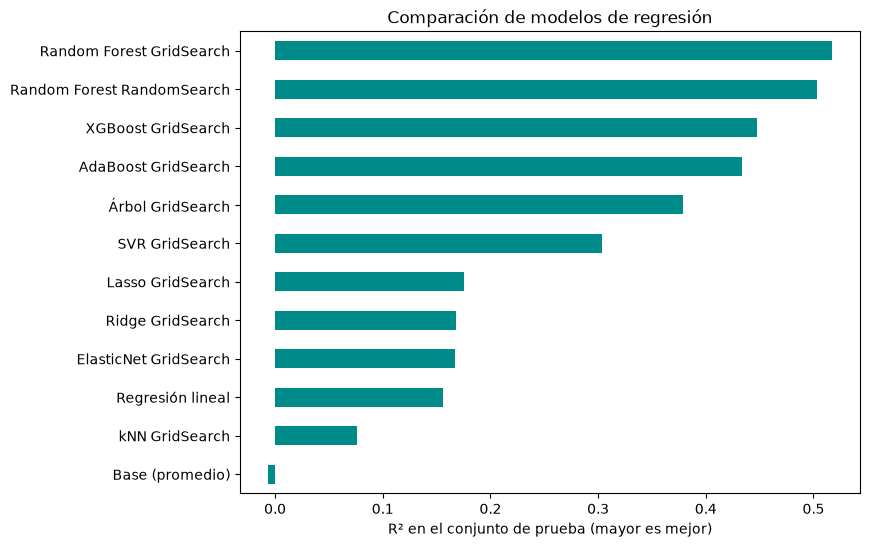

In [64]:
res_reg = pd.DataFrame(resultados_reg).T.sort_values("R2", ascending=False)
display(res_reg.round(4))

res_reg["R2"].sort_values().plot(kind="barh", figsize=(8, 6), color="darkcyan")
plt.xlabel("R² en el conjunto de prueba (mayor es mejor)"); plt.title("Comparación de modelos de regresión"); plt.show()

In [65]:
# Robustez: R² en validación cruzada de 5 particiones (con Pipeline para no tener data leakage)
from sklearn.model_selection import KFold
cv_r = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
candidatos_reg = {
    "Regresión lineal": LinearRegression(),
    "Lasso": gs_lasso.best_estimator_,
    "kNN": gs_knn_r.best_estimator_,
    "Árbol": gs_arbol_r.best_estimator_,
    "Random Forest": gs_rf_r.best_estimator_,
    "AdaBoost": gs_ada_r.best_estimator_,
    "XGBoost": gs_xgb_r.best_estimator_,
    "SVR": gs_svr.best_estimator_,
}
filas = []
for nombre, modelo in candidatos_reg.items():
    pipe = Pipeline([("scaler", StandardScaler()), ("modelo", modelo)])
    r2_cv = cross_val_score(pipe, Xr_train, yr_train, cv=cv_r, scoring="r2")
    mae_cv = -cross_val_score(pipe, Xr_train, yr_train, cv=cv_r, scoring="neg_mean_absolute_error")
    filas.append({"Modelo": nombre, "R2 promedio": r2_cv.mean(), "R2 desv.": r2_cv.std(), "MAE promedio": mae_cv.mean()})
pd.DataFrame(filas).set_index("Modelo").sort_values("R2 promedio", ascending=False).round(3)

,R2 promedio,R2 desv.,MAE promedio
Modelo,,,
Random Forest,0.504,0.044,0.079
XGBoost,0.492,0.048,0.082
AdaBoost,0.410,0.029,0.093
SVR,0.341,0.093,0.100
Árbol,0.303,0.110,0.097
kNN,0.180,0.070,0.117
Regresión lineal,0.076,0.444,0.111
Lasso,0.059,0.476,0.110


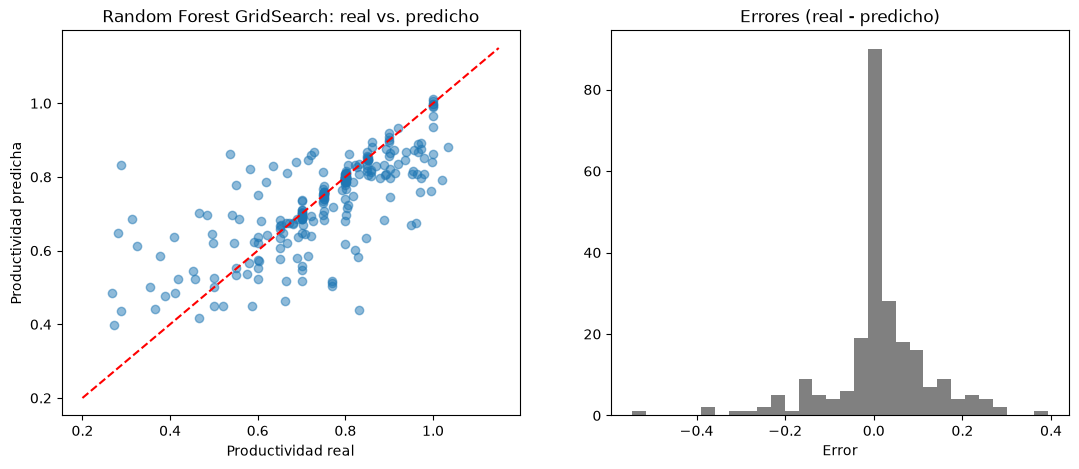

Coeficientes más grandes de Lasso (variables estandarizadas):
no_of_workers            0.0978
smv                     -0.0740
targeted_productivity    0.0682
team_11                 -0.0275
team_7                  -0.0263
idle_men                -0.0253
team_10                 -0.0250
team_9                  -0.0211
department_sewing       -0.0203
team_6                  -0.0183
dtype: float64


In [66]:
mejor_reg_nombre = res_reg.index[0]
mejor_reg = {"Random Forest GridSearch": gs_rf_r.best_estimator_, "Random Forest RandomSearch": rs_rf_r.best_estimator_,
             "XGBoost GridSearch": gs_xgb_r.best_estimator_, "AdaBoost GridSearch": gs_ada_r.best_estimator_,
             "Árbol GridSearch": gs_arbol_r.best_estimator_, "SVR GridSearch": gs_svr.best_estimator_,
             "kNN GridSearch": gs_knn_r.best_estimator_}.get(mejor_reg_nombre, gs_rf_r.best_estimator_)

pred_mejor = mejor_reg.predict(Xr_test_s)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(yr_test, pred_mejor, alpha=0.5)
ax[0].plot([0.2, 1.15], [0.2, 1.15], linestyle="--", color="red")
ax[0].set_xlabel("Productividad real"); ax[0].set_ylabel("Productividad predicha")
ax[0].set_title(f"{mejor_reg_nombre}: real vs. predicho")
ax[1].hist(yr_test - pred_mejor, bins=30, color="gray")
ax[1].set_title("Errores (real - predicho)"); ax[1].set_xlabel("Error")
plt.show()

# Coeficientes de la regresión lineal (Lasso): cómo cambia la productividad con cada variable
coef_lasso = pd.Series(gs_lasso.best_estimator_.coef_, index=X.columns)
print("Coeficientes más grandes de Lasso (variables estandarizadas):")
print(coef_lasso.reindex(coef_lasso.abs().sort_values(ascending=False).index).head(10).round(4))



| Modelo | Error promedio (MAE) | R² |
|---|---|---|
| Base (siempre el promedio) | 0.127 | 0.00 |
| Regresión lineal / Ridge / Lasso | ≈ 0.109 | ≈ 0.17 |
| kNN | 0.116 | 0.08 |
| SVR | 0.096 | 0.30 |
| Árbol | 0.087 | 0.38 |
| AdaBoost | 0.086 | 0.43 |
| XGBoost | 0.079 | 0.45 |
|  **Random Forest** | **0.072** | **0.52** |


- El **Random Forest** es el mejor: se equivoca en promedio **7 puntos** de productividad y explica cerca de la **mitad** de los cambios.
- Las **regresiones lineales casi no sirven** (y en la validación cruzada cambian mucho): la relación **no es una línea recta**.
- En la gráfica "real vs. predicho", los puntos cerca de la línea roja son aciertos. El modelo acierta bien de 0.7 a 1.0, pero le cuesta con los días **muy malos** (< 0.5).
- **Lasso** (dirección del efecto): más **trabajadores** y **meta** más alta → más productividad; tareas más complejas (**SMV**), **paros** y algunos **equipos** → menos productividad.

 **Para qué le sirve a la fábrica:** estimar **antes del día** cuánto va a producir cada equipo y poner metas **alcanzables**.

## 6. Regresión logística


== LogReg base == accuracy = 0.7792 | F1 = 0.4646 | AUC = 0.7482
              precision    recall  f1-score   support

  Cumple (0)       0.80      0.94      0.86       175
Incumple (1)       0.68      0.35      0.46        65

    accuracy                           0.78       240
   macro avg       0.74      0.65      0.66       240
weighted avg       0.76      0.78      0.75       240



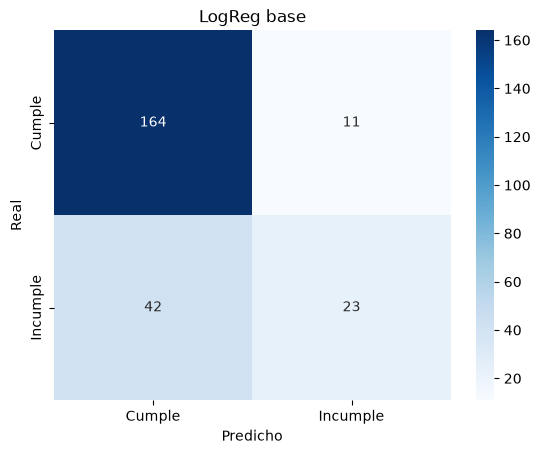

Mejores parámetros: {'C': 10, 'class_weight': 'balanced', 'penalty': 'l2'} | CV score: 0.5344
== LogReg GridSearch == accuracy = 0.6750 | F1 = 0.5125 | AUC = 0.7505
Mejores parámetros: {'C': np.float64(14.528246637516036), 'class_weight': 'balanced', 'penalty': 'l2'} | CV score: 0.5344
== LogReg RandomSearch == accuracy = 0.6750 | F1 = 0.5125 | AUC = 0.7506


In [67]:
# (a) Base
logreg = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
logreg.fit(X_train_s, y_train)
evaluar("LogReg base", logreg)

# (b) GridSearchCV sobre C y penalty
param_grid_lr = {"C": [0.01, 0.1, 1, 10], "penalty": ["l1", "l2"], "class_weight": [None, "balanced"]}
gs_lr = GridSearchCV(LogisticRegression(solver="liblinear", max_iter=2000, random_state=RANDOM_STATE),
                     param_grid_lr, cv=5, scoring="f1", n_jobs=-1)
gs_lr.fit(X_train_s, y_train)
print("Mejores parámetros:", gs_lr.best_params_, "| CV score:", round(gs_lr.best_score_, 4))
evaluar("LogReg GridSearch", gs_lr.best_estimator_, mostrar=False)

# (c) RandomizedSearchCV (loguniform para C)
rs_lr = RandomizedSearchCV(LogisticRegression(solver="liblinear", max_iter=2000, random_state=RANDOM_STATE),
                           {"C": loguniform(1e-3, 1e2), "penalty": ["l1", "l2"], "class_weight": [None, "balanced"]},
                           n_iter=20, cv=5, scoring="f1", random_state=RANDOM_STATE, n_jobs=-1)
rs_lr.fit(X_train_s, y_train)
print("Mejores parámetros:", rs_lr.best_params_, "| CV score:", round(rs_lr.best_score_, 4))
evaluar("LogReg RandomSearch", rs_lr.best_estimator_, mostrar=False)

F1 ≈ 0.51. Detecta bastantes equipos que no cumplen (recall 0.63) pero con muchas falsas alarmas. Al ser un modelo de "línea recta", se queda corto.

## 8. Comparación final de los modelos de clasificación
La tabla está ordenada del mejor al peor según el **F1**.

,Accuracy,Precisión,Recall,F1,ROC-AUC,Costo (3·FN+FP)
RandomForest GridSearch,0.829,0.682,0.692,0.687,0.840,81.0
Árbol RandomSearch,0.846,0.769,0.615,0.684,0.827,87.0
XGBoost GridSearch,0.825,0.677,0.677,0.677,0.834,84.0
RandomForest RandomSearch,0.821,0.667,0.677,0.672,0.843,85.0
XGBoost RandomSearch,0.796,0.608,0.692,0.647,0.829,89.0
AdaBoost GridSearch,0.821,0.712,0.569,0.632,0.829,99.0
AdaBoost base,0.817,0.698,0.569,0.627,0.832,100.0
XGBoost base,0.808,0.679,0.554,0.610,0.830,104.0
Árbol GridSearch,0.812,0.700,0.538,0.609,0.825,105.0
RandomForest base,0.808,0.702,0.508,0.589,0.844,110.0


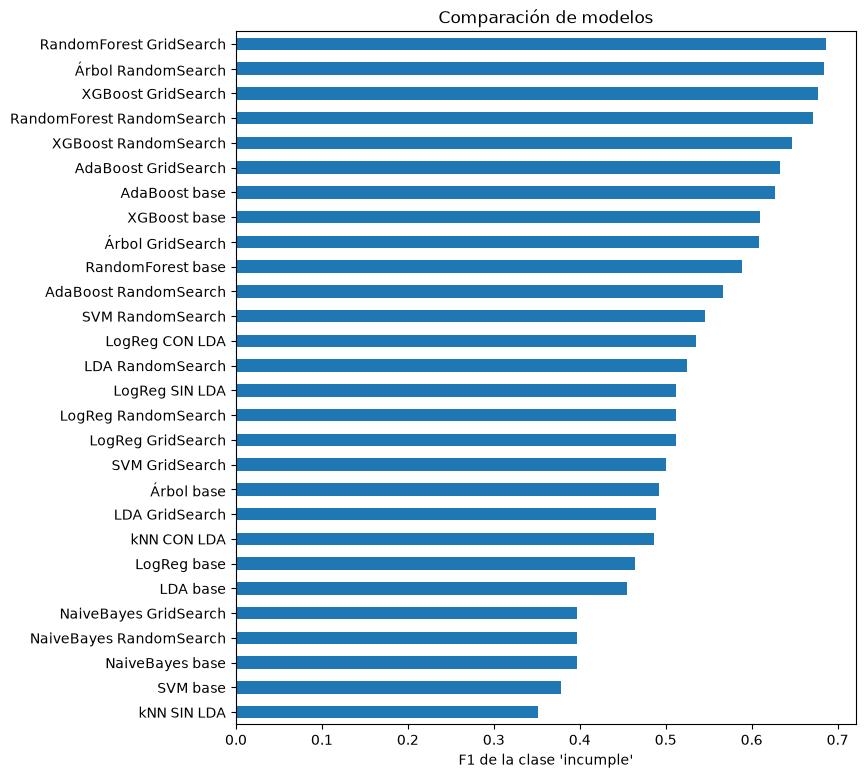

In [68]:
res = pd.DataFrame(resultados).T.sort_values("F1", ascending=False)
display(res.round(3))

res["F1"].sort_values().plot(kind="barh", figsize=(8, 9))
plt.xlabel("F1 de la clase 'incumple'"); plt.title("Comparación de modelos"); plt.show()

 arriba quedan los modelos de **árboles** (Random Forest, XGBoost, Árbol, AdaBoost) y abajo Naive Bayes y kNN.

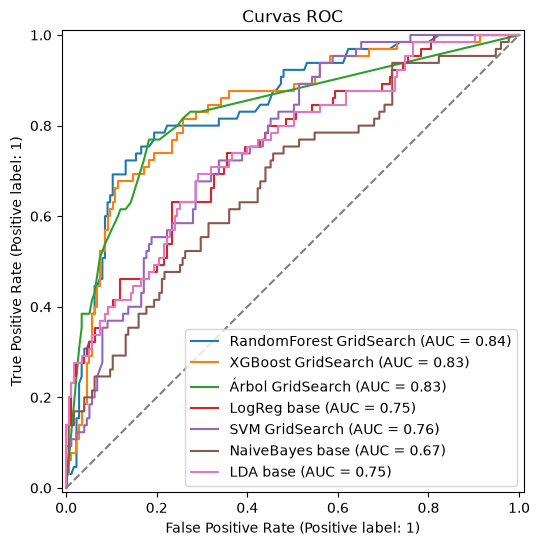

In [69]:
# Curvas ROC de los mejores de cada familia
fig, ax = plt.subplots(figsize=(7, 6))
for nombre, modelo in [("RandomForest GridSearch", gs_rf.best_estimator_), ("XGBoost GridSearch", gs_xgb.best_estimator_),
                       ("Árbol GridSearch", gs_arbol.best_estimator_), ("LogReg base", logreg),
                       ("SVM GridSearch", gs_svm.best_estimator_), ("NaiveBayes base", nb), ("LDA base", lda)]:
    RocCurveDisplay.from_estimator(modelo, X_test_s, y_test, name=nombre, ax=ax)
ax.plot([0, 1], [0, 1], linestyle="--", color="gray"); ax.set_title("Curvas ROC"); plt.show()

 las curvas ROC: mientras más pegada esté la curva a la **esquina de arriba a la izquierda**, mejor. La línea punteada es "adivinar al azar". El Random Forest y el XGBoost son los mejores.

### 8.1  (validación cruzada)


In [70]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
candidatos = {
    "NaiveBayes": GaussianNB(),
    "LogReg": gs_lr.best_estimator_,
    "LDA": LinearDiscriminantAnalysis(),
    "Árbol": gs_arbol.best_estimator_,
    "RandomForest": gs_rf.best_estimator_,
    "AdaBoost": gs_ada.best_estimator_,
    "XGBoost": gs_xgb.best_estimator_,
    "SVM": gs_svm.best_estimator_,
}
filas_cv = []
for nombre, modelo in candidatos.items():
    pipe = Pipeline([("scaler", StandardScaler()), ("modelo", modelo)])
    f1_cv = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1")
    auc_cv = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc")
    filas_cv.append({"Modelo": nombre, "F1 promedio": f1_cv.mean(), "F1 desv.": f1_cv.std(),
                     "AUC promedio": auc_cv.mean(), "AUC desv.": auc_cv.std()})
pd.DataFrame(filas_cv).set_index("Modelo").sort_values("F1 promedio", ascending=False).round(3)

,F1 promedio,F1 desv.,AUC promedio,AUC desv.
Modelo,,,,
RandomForest,0.638,0.043,0.859,0.029
XGBoost,0.632,0.036,0.846,0.027
AdaBoost,0.576,0.016,0.839,0.029
Árbol,0.571,0.052,0.782,0.026
SVM,0.540,0.046,0.759,0.032
LogReg,0.520,0.024,0.733,0.029
LDA,0.453,0.044,0.735,0.037
NaiveBayes,0.452,0.006,0.676,0.023


 el **Random Forest queda primero** en los 5 exámenes (AUC 0.86 ± 0.03). El "±" pequeño significa que es **estable**: no fue suerte.

### 8.2 Ajustar el "límite" del modelo según el costo


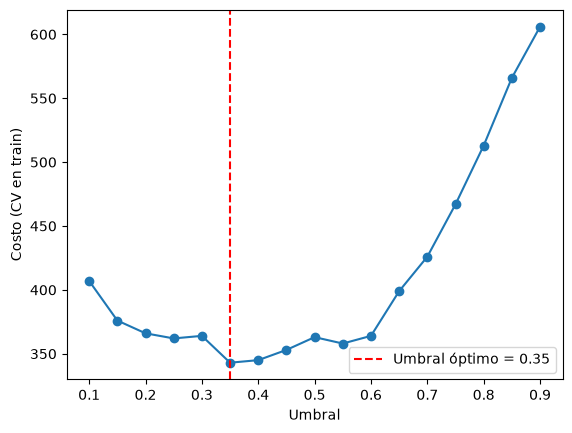

Umbral 0.50: recall = 0.692 | precisión = 0.682 | FN = 20 | FP = 21 | costo = 81
Umbral 0.35: recall = 0.785 | precisión = 0.573 | FN = 14 | FP = 38 | costo = 80


In [71]:
modelo_final = gs_rf.best_estimator_
prob_cv = cross_val_predict(modelo_final, X_train_s, y_train, cv=cv, method="predict_proba")[:, 1]

umbrales = np.arange(0.10, 0.91, 0.05)
costos = []
for u in umbrales:
    tn, fp, fn, tp = confusion_matrix(y_train, (prob_cv >= u).astype(int)).ravel()
    costos.append(COSTO_FN * fn + COSTO_FP * fp)
umbral_optimo = umbrales[int(np.argmin(costos))]

plt.plot(umbrales, costos, marker="o")
plt.axvline(umbral_optimo, linestyle="--", color="red", label=f"Umbral óptimo = {umbral_optimo:.2f}")
plt.xlabel("Umbral"); plt.ylabel("Costo (CV en train)"); plt.legend(); plt.show()

prob_test = modelo_final.predict_proba(X_test_s)[:, 1]
for u in [0.5, umbral_optimo]:
    pred_u = (prob_test >= u).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred_u).ravel()
    print(f"Umbral {u:.2f}: recall = {recall_score(y_test, pred_u):.3f} | precisión = {precision_score(y_test, pred_u):.3f} "
          f"| FN = {fn} | FP = {fp} | costo = {COSTO_FN * fn + COSTO_FP * fp}")

 con el límite en **35 %**, el modelo detecta **79 %** de los equipos que no cumplen (antes 69 %), a cambio de más falsas alarmas (de 21 a 38). El costo total es casi igual (80 vs. 81): la fábrica decide qué prefiere.

## Conclusiones de la Fase 4

###  Modelo elegido: Random Forest (ajustado con GridSearch)
| Modelo | F1 | Recall | AUC | Costo | Validación cruzada (F1 / AUC) |
|---|---|---|---|---|---|
| **Random Forest** | **0.69** | **0.69** | 0.84 | **81** | **0.64 / 0.86** |
| XGBoost | 0.68 | 0.68 | 0.83 | 84 | 0.63 / 0.85 |
| Árbol de decisión | 0.68 | 0.62 | 0.83 | 87 | 0.57 / 0.78 |
| AdaBoost | 0.63 | 0.57 | 0.83 | 99 | 0.58 / 0.84 |
| SVM | 0.55 | 0.65 | 0.76 | 116 | 0.54 / 0.76 |
| Regresión logística | 0.51 | 0.63 | 0.75 | 126 | 0.52 / 0.73 |
| LDA | 0.46 | 0.35 | 0.75 | 139 | 0.45 / 0.74 |
| Naive Bayes | 0.40 | 0.34 | 0.67 | 153 | 0.45 / 0.68 |

**¿Por qué Random Forest?**
1. Tiene el **mejor F1, el mejor recall y el menor costo** del error.
2. En los **5 exámenes** (validación cruzada) también sale **primero** → **no fue suerte**.
3. Detecta **7 de cada 10** equipos que no van a cumplir. Si bajamos el límite a **35 %**, detecta **8 de cada 10** (con más falsas alarmas, pero el costo total es casi igual: 80 vs. 81).
4. XGBoost queda casi empatado, pero Random Forest es más fácil de explicar.

**¿Sirvió ajustar las perillas (GridSearch)?** Sí: el Random Forest pasó de F1 **0.59 a 0.69**. Lo que más ayudó fue `class_weight="balanced"`, que obliga al modelo a prestar atención a los que no cumplen (que son pocos).

**¿El modelo se aprendió los datos de memoria (sobreajuste)?** No de forma grave: en la validación cruzada (0.64) y en el examen final (0.69) le va parecido.

### Respuesta a las hipótesis
| Hipótesis | Resultado |
|---|---|
| H1: los cambios de estilo bajan la productividad | **Sí** (grupo "costura con cambio de estilo" = el más bajo) |
| H2: hay equipos que rinden peor siempre | **Sí** (equipos 6, 7, 8, 10 y 11 en LDA y Lasso) |
| H3: acabado es más inestable | **Sí** (solo 65 % cumple en ese grupo) |
| H4: el incentivo ayuda a cumplir | **Sí** (sin incentivo 44 % no cumple; con incentivo, 9 %) |
| H5: se puede anticipar quién no va a cumplir | **En parte** (detectamos 7–8 de cada 10, AUC 0.84) |

### Resumen de las 4 técnicas
- **Clustering:** 3 tipos de jornada; acabado es el más inestable y los cambios de estilo bajan la productividad.
- **PCA:** sirve para dibujar y entender (tamaño de la operación, paros, incentivo), no para mejorar los modelos.
- **LDA:** mejora al kNN, pero una línea recta no alcanza; los árboles funcionan mejor.
- **Clasificación y regresión:** el **Random Forest** gana en las dos.

### Limitaciones
- Solo 1197 registros de **3 meses** y de **una fábrica**.
- El costo 3 a 1 es un **supuesto**.
- Faltan datos como la experiencia de los operarios o el estado de las máquinas.